# NASA Space Apps 2026 — EDA da Biological Data API (OSDR)

**Desafio:** criar uma ferramenta visual para que astronautas avaliem a própria saúde durante missões e recebam orientações de prevenção/tratamento.

**Fonte de dados deste notebook:** [NASA OSDR – Biological Data API (BDAPI)](https://visualization.osdr.nasa.gov/biodata/api/) · [tutorial oficial](https://osdr-tutorials.readthedocs.io/en/latest/pages/guides/biological_data_api.html)

---

### O que este notebook responde

| # | Pergunta | Seção |
|---|----------|-------|
| 1 | Como a API é organizada e em que **formato** os dados chegam (JSON REST, CSV, modelo ISA)? | 2 |
| 2 | Quantos estudos (datasets) existem, de quando são e o que cada um descreve? | 3 |
| 3 | Que **tipos de ensaio** (RNA-seq, proteômica, metabolômica, …) e **organismos** existem? | 4 |
| 4 | O que há no nível de **amostra** (tecido, fatores experimentais, variáveis de estudo)? | 5 |
| 5 | Que **arquivos/tabelas quantitativas** a API consegue entregar direto (contagens, DGE, PCA)? | 6, 8 |
| 6 | Que partes do repositório são **relevantes para um app de autoavaliação de saúde de astronautas**? (os 5 *hazards* da NASA HRP × sistemas do corpo × indicadores) | 7 |
| 7 | Como **extrair só o que importa** e exportar para o projeto? | 9 |

### Como usar
1. Rode as células **de cima para baixo** (`Ambiente de execução → Executar tudo`).
2. Toda requisição é **cacheada** na pasta `osdr_cache/` — reexecutar é rápido.
3. Os parâmetros ajustáveis estão na célula **1.2** (por exemplo, limitar o nº de datasets para um teste rápido).
4. Os pesos do *score* de relevância (seção 7.6) são **heurísticos** e foram feitos para o time editar.

> ⚠️ **Contexto importante:** o OSDR é um repositório de **ciência biológica de voo espacial** (ômicas, fisiologia, imagens) — majoritariamente de roedores, plantas e micro-organismos, com alguns estudos humanos. Ele **não** é um repositório de sinais vitais (pressão, FC, glicemia, …) coletados de astronautas. Parte do objetivo do EDA é medir exatamente **o que dá para aproveitar** (e o que precisa vir de outra fonte).

## 1. Setup
### 1.1 Bibliotecas e helpers

In [7]:
import re, io, os, json, time, hashlib, warnings
from urllib.parse import quote
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 80)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

BASE = "https://visualization.osdr.nasa.gov/biodata/api"
CACHE_DIR = "osdr_cache"
OUT_DIR = "outputs"
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

SESSION = requests.Session()
SESSION.headers.update({"User-Agent": "nasa-space-apps-2026-osdr-eda/1.0"})


# ---------- acesso à API (toda a rede passa por http_get) ----------
def http_get(url, timeout=240, retries=3, use_cache=True):
    """GET com cache em disco e retentativas. Devolve texto."""
    key = hashlib.md5(url.encode("utf-8")).hexdigest()
    path = os.path.join(CACHE_DIR, key + ".txt")
    if use_cache and os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            return f.read()
    last = None
    for i in range(retries):
        try:
            r = SESSION.get(url, timeout=timeout)
            if r.status_code == 200:
                r.encoding = r.encoding or "utf-8"
                txt = r.text
                if use_cache:
                    with open(path, "w", encoding="utf-8") as f:
                        f.write(txt)
                return txt
            last = f"HTTP {r.status_code}"
            if r.status_code in (400, 404):
                break                      # não adianta tentar de novo
        except requests.RequestException as e:
            last = repr(e)
        time.sleep(2 ** i)
    raise RuntimeError(f"Falha em {url[:220]} -> {last}")


def build_url(path, params=None, fmt=None):
    """Monta a URL da BDAPI.
    params: lista de (campo, valor). valor=None => campo 'solto' (vira coluna, sem filtro).
    Espaços viram %20; '|' (OR) é preservado."""
    parts = []
    for k, v in (params or []):
        kk = quote(k, safe=".")
        parts.append(kk if v is None else f"{kk}={quote(str(v), safe='|')}")
    if fmt:
        parts.append(f"format={fmt}")
    return f"{BASE}{path}" + ("?" + "&".join(parts) if parts else "")


ID_COLS = {
    "datasets": ["id.accession"],
    "assays":   ["id.accession", "id.assay name"],
    "samples":  ["id.accession", "id.assay name", "id.sample name"],
}

def query_table(level, params=None, force_legacy=False):
    """Consulta tabular. level ∈ {'datasets','assays','samples'}.
    1º tenta o endpoint novo (/v2/query/<level>/); se falhar, cai para o legado
    descrito no tutorial (/v2/query/metadata/) e deduplica no nível pedido.
    Devolve (DataFrame, modo_usado)."""
    e_new = "ignorado (force_legacy)"
    if not force_legacy:
        try:
            txt = http_get(build_url(f"/v2/query/{level}/", params))
            return pd.read_csv(io.StringIO(txt), low_memory=False), f"v2/query/{level}"
        except Exception as e:
            e_new = e
    try:
        txt = http_get(build_url("/v2/query/metadata/", params))
    except Exception as e_old:
        raise RuntimeError(f"Os dois endpoints falharam.\n novo: {e_new}\n legado: {e_old}")
    df = pd.read_csv(io.StringIO(txt), low_memory=False)
    keys = [k for k, _ in (params or [])]
    keep = [c for c in df.columns
            if c in ID_COLS[level] or any(c.startswith(k) for k in keys)]
    df = df[keep].drop_duplicates().reset_index(drop=True)
    return df, "legado v2/query/metadata (deduplicado)"


# ---------- utilidades ----------
def pick(df, pattern):
    """Primeira coluna cujo nome casa com o regex."""
    for c in df.columns:
        if re.search(pattern, c, re.I):
            return c
    return None

def pick_all(df, pattern):
    return [c for c in df.columns if re.search(pattern, c, re.I)]

def flatten(d, prefix="", sep="."):
    """Achata dicionários aninhados (JSON REST) em chaves 'a.b.c'."""
    out = {}
    if isinstance(d, dict):
        for k, v in d.items():
            out.update(flatten(v, f"{prefix}{sep}{k}" if prefix else str(k), sep))
    elif isinstance(d, list):
        out[prefix] = "; ".join(map(str, d))
    else:
        out[prefix] = d
    return out

def show_tree(obj, depth=0, max_depth=4, max_items=6, indent="  "):
    """Imprime a estrutura de um JSON de forma compacta."""
    pad = indent * depth
    if isinstance(obj, dict):
        for i, (k, v) in enumerate(obj.items()):
            if i >= max_items:
                print(f"{pad}… (+{len(obj) - max_items} chaves)")
                break
            if isinstance(v, (dict, list)) and depth < max_depth:
                print(f"{pad}{k}: {type(v).__name__}({len(v)})")
                show_tree(v, depth + 1, max_depth, max_items, indent)
            else:
                print(f"{pad}{k}: {repr(v)[:90]}")
    elif isinstance(obj, list):
        for v in obj[:3]:
            show_tree(v, depth + 1, max_depth, max_items, indent)

def barh(series, title, top=20, xlabel="", color=None, ax=None, figsize=(8, 5)):
    """Barras horizontais ordenadas, com valores anotados."""
    s = series.sort_values(ascending=False).head(top)[::-1]
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    ax.barh(s.index.astype(str), s.values, color=color or sns.color_palette("deep")[0])
    for y, v in enumerate(s.values):
        ax.text(v, y, f" {v:,.0f}" if float(v).is_integer() else f" {v:,.2f}", va="center", fontsize=8)
    ax.set_title(title); ax.set_xlabel(xlabel)
    ax.margins(x=0.12)
    return ax

def organism_group(o):
    o = str(o).lower().strip()
    if o in ("", "nan", "none"):                              return "Não informado"
    if "homo sapiens" in o:                                   return "Humano"
    if "mus musculus" in o:                                   return "Camundongo"
    if "rattus" in o:                                         return "Rato"
    if re.search(r"macaca|sus scrofa|canis|danio|xenopus|oryzias|gallus|drosophila|caenorhabditis|"
                 r"bombyx|apis|schistosoma|artemia|daphnia|tardigra|nematod|planari|hydra|callithrix|papio", o):
        return "Outros animais"
    if re.search(r"arabidopsis|oryza|brassica|zea mays|solanum|triticum|lactuca|pisum|physcomitrella|"
                 r"glycine|medicago|plant|nicotiana|hordeum|marchantia|ceratopteris", o):
        return "Planta"
    if re.search(r"escherichia|bacillus|staphylo|pseudomonas|salmonella|saccharomyces|candida|aspergillus|"
                 r"streptomyces|bacter|yeast|fung|archaea|microb|virus|cupriavidus|deinococcus|lactobacillus|"
                 r"klebsiella|enterobacter|serratia|mycobacter|synechoc|chlamydomonas|methano|penicillium|cladospor", o):
        return "Micro-organismo"
    return "Outro"

### 1.2 Parâmetros do notebook

In [8]:
# ----- parâmetros que o time pode ajustar -----
FETCH_DATASET_METADATA     = True   # busca /v2/dataset/<OSD>/ de cada estudo (1 requisição por estudo, em threads)
MAX_DATASETS_FOR_META      = None   # ex.: 150 para um teste rápido; None = todos
N_DATASETS_FILE_INVENTORY  = 30     # quantos datasets "top" terão os arquivos listados (seção 6.2)
N_THREADS                  = 8
print("OK — parâmetros definidos")

OK — parâmetros definidos


## 2. Estrutura da API e formatos de resposta

A BDAPI (v2.0.0, especificação OpenAPI) tem **dois estilos de endpoint**:

| Estilo | Endpoint | Formato | Para quê |
|---|---|---|---|
| **REST** (navegar) | `/v2/datasets/` | JSON | lista todos os estudos (`OSD-###`) com a URL REST de cada um |
| | `/v2/dataset/{OSD}/` | JSON | metadados do estudo + links para *assays* e *files* |
| | `/v2/dataset/{OSD}/assays/` · `/assay/{nome}/` | JSON | ensaios do estudo |
| | `/v2/dataset/{OSD}/assay/{nome}/samples/` · `/sample/{nome}/` | JSON | amostras e **metadados ISA** completos |
| | `/v2/dataset/{OSD}/files/` · `/file/{nome}/` | JSON | arquivos + URL de download direto |
| **Query** (analisar) | `/v2/query/datasets/` · `/assays/` · `/samples/` | **CSV** (padrão), TSV, `json.records`, `json.table`, `json.split` | tabelas filtráveis por metadados |
| **Legado (tutorial)** | `/v2/query/metadata/` · `/v2/query/data/` | CSV | tabela de metadados por amostra×arquivo; **tabelas de dados** (contagens, DGE, PCA…) |

**Sintaxe dos filtros** (na *query string*): o nome do campo segue o modelo **ISA** — `study.characteristics.organism`, `study.factor value.spaceflight`, `assay.parameter value.sequencing instrument`, mais atalhos `id.accession`, `id.assay name`, `id.sample name`, `file.datatype`.
`campo=valor` filtra · `campo!=valor` exclui · `a|b` é OR · `campo` sem valor **adiciona a coluna sem filtrar** · soltar o último nível (`study.characteristics`) traz **todas as colunas do grupo**.

A seguir, testamos a conectividade e vemos o formato *real* de cada resposta.

### 2.1 Lista de estudos (`/v2/datasets/`) — JSON

In [9]:
raw_ds = json.loads(http_get(build_url("/v2/datasets/")))

df_ds = pd.DataFrame({
    "accession": list(raw_ds.keys()),
    "rest_url":  [v.get("REST_URL") for v in raw_ds.values()],
})
df_ds["osd_num"] = df_ds["accession"].str.extract(r"(\d+)").astype(int)
df_ds = df_ds.sort_values("osd_num").reset_index(drop=True)

print(f"✅ API respondeu. Estudos públicos listados: {len(df_ds)}")
print(f"   Faixa de IDs: OSD-{df_ds.osd_num.min()} … OSD-{df_ds.osd_num.max()}")
display(df_ds.head(8))

✅ API respondeu. Estudos públicos listados: 645
   Faixa de IDs: OSD-1 … OSD-1015


,accession,rest_url,osd_num
0,OSD-1,https://visualization.osdr.nasa.gov/biodata/api/v2/dataset/OSD-1/,1
1,OSD-2,https://visualization.osdr.nasa.gov/biodata/api/v2/dataset/OSD-2/,2
2,OSD-3,https://visualization.osdr.nasa.gov/biodata/api/v2/dataset/OSD-3/,3
3,OSD-4,https://visualization.osdr.nasa.gov/biodata/api/v2/dataset/OSD-4/,4
4,OSD-5,https://visualization.osdr.nasa.gov/biodata/api/v2/dataset/OSD-5/,5
5,OSD-6,https://visualization.osdr.nasa.gov/biodata/api/v2/dataset/OSD-6/,6
6,OSD-7,https://visualization.osdr.nasa.gov/biodata/api/v2/dataset/OSD-7/,7
7,OSD-8,https://visualization.osdr.nasa.gov/biodata/api/v2/dataset/OSD-8/,8


### 2.2 Um estudo por dentro — da raiz até uma **amostra** (JSON hierárquico)
Esta é a "anatomia" dos dados: `dataset → assays → samples → metadata (ISA)`.

In [10]:
EXAMPLE = "OSD-48" if "OSD-48" in raw_ds else df_ds.accession.iloc[0]
print("Estudo de exemplo:", EXAMPLE)

print("\n▶ /v2/dataset/<OSD>/")
ds_json = json.loads(http_get(build_url(f"/v2/dataset/{EXAMPLE}/")))
show_tree(ds_json, max_depth=3)

print("\n▶ /v2/dataset/<OSD>/assays/")
assays_json = json.loads(http_get(build_url(f"/v2/dataset/{EXAMPLE}/assays/")))
ex_assays = list(assays_json[EXAMPLE]["assays"].keys())
print(f"{len(ex_assays)} ensaio(s):")
for a in ex_assays[:5]:
    print("  -", a)

ex_assay = ex_assays[0]
print("\n▶ .../assay/<ensaio>/samples/")
samples_json = json.loads(http_get(build_url(f"/v2/dataset/{EXAMPLE}/assay/{quote(ex_assay, safe='')}/samples/")))
ex_samples = list(samples_json[EXAMPLE]["assays"][ex_assay]["samples"].keys())
print(f"{len(ex_samples)} amostra(s). Primeiras:", ex_samples[:4])

print("\n▶ .../sample/<amostra>/  (metadados ISA da amostra)")
ex_sample = ex_samples[0]
sample_json = json.loads(http_get(build_url(
    f"/v2/dataset/{EXAMPLE}/assay/{quote(ex_assay, safe='')}/sample/{quote(ex_sample, safe='')}/")))
show_tree(sample_json, max_depth=6, max_items=8)

Estudo de exemplo: OSD-48

▶ /v2/dataset/<OSD>/
OSD-48: dict(4)
  REST_URL: 'https://visualization.osdr.nasa.gov/biodata/api/v2/dataset/OSD-48/'
  assays: dict(1)
    REST_URL: 'https://visualization.osdr.nasa.gov/biodata/api/v2/dataset/OSD-48/assays/'
  files: dict(1)
    REST_URL: 'https://visualization.osdr.nasa.gov/biodata/api/v2/dataset/OSD-48/files/'
  metadata: dict(39)
    authoritative source url: 'OSD-48/'
    flight program: ''
    mission: dict(3)
      end date: '10/25/2014'
      start date: '9/21/14'
      name: 'SpaceX-4'
    material type: 'Liver'
    project identifier: 'RR-1'
    accession: 'OSD-48'
    … (+33 chaves)

▶ /v2/dataset/<OSD>/assays/
5 ensaio(s):
  - OSD-48_transcription-profiling_rna-sequencing-(rna-seq)_Illumina
  - OSD-48_protein-expression-profiling_mass-spectrometry_Orbitrap Fusion(Thermo Scientific)
  - OSD-48_molecular-cellular-imaging_microscopy_pannoramic scan (3d histech)
  - OSD-48_dna-methylation-profiling_whole-genome-bisulfite-sequencing_Il

### 2.3 Correspondência entre o JSON hierárquico e as colunas das tabelas
O JSON de uma amostra, achatado com `flatten()`, gera **exatamente os nomes de campo** que usamos nos filtros/colunas das consultas `query`.

In [14]:
ex_meta = sample_json[EXAMPLE]["assays"][ex_assay]["samples"][ex_sample].get("metadata", {})
flat = flatten(ex_meta)
df_flat = pd.DataFrame({"campo (nome usado na query)": list(flat.keys()), "valor": [str(v)[:80] for v in flat.values()]})
df_flat["grupo ISA"] = df_flat["campo (nome usado na query)"].str.split(".").str[:2].str.join(".")
print(f"A amostra '{ex_sample}' tem {len(df_flat)} campos de metadados, em {df_flat['grupo ISA'].nunique()} grupos ISA.")
display(df_flat.groupby("grupo ISA").size().rename("n_campos").to_frame())
display(df_flat.head(25))

A amostra 'Mmus_C57-6J_LVR_FLT_C_Rep1_M25' tem 302 campos de metadados, em 22 grupos ISA.


,n_campos
grupo ISA,
assay.assay name,3
assay.extract name,3
assay.parameter value,111
assay.raw data file,3
assay.sample name,3
id.accession,1
id.assay name,1
id.sample name,1
id.study name,1


,campo (nome usado na query),valor,grupo ISA
0,id.accession,OSD-48,id.accession
1,id.assay name,OSD-48_transcription-profiling_rna-sequencing-(rna-seq)_Illumina,id.assay name
2,id.sample name,Mmus_C57-6J_LVR_FLT_C_Rep1_M25,id.sample name
3,id.study name,OSD-48,id.study name
4,investigation.ontology source reference,"{'term source name': 'RBO', 'term source file': '', 'term source version': '', '",investigation.ontology source reference
5,investigation.study design descriptors,"{'study design type': 'low Earth orbit', 'study design type term accession numbe",investigation.study design descriptors
6,investigation.study publications,"{'study pubmed id': 30044882, 'study publication doi': '10.1371/journal.pone.019",investigation.study publications
7,investigation.study factors,"{'study factor name': 'Spaceflight', 'study factor type': 'Space Flight', 'study",investigation.study factors
8,investigation.study protocols,"{'study protocol name': 'Animal Husbandry', 'study protocol type': 'Animal Husba",investigation.study protocols
9,investigation.study contacts,"{'study person last name': 'Globus', 'study person first name': 'Ruth', 'study p",investigation.study contacts


### 2.4 Formato **tabular** (CSV) — como chega uma consulta `query`

In [15]:
demo_url = build_url("/v2/query/samples/", [("study.characteristics.organism", "mus musculus"),
                                            ("study.factor value.spaceflight", None)])
print("URL de exemplo:\n ", demo_url, "\n")
try:
    demo_txt = http_get(demo_url)
except Exception as e:
    print("endpoint novo indisponível, usando o legado:", str(e)[:120])
    demo_txt = http_get(build_url("/v2/query/metadata/", [("study.characteristics.organism", "mus musculus"),
                                                          ("study.factor value.spaceflight", None)]))
print("Primeiros caracteres da resposta (CSV bruto):\n")
print(demo_txt[:700])
demo_df = pd.read_csv(io.StringIO(demo_txt), low_memory=False)
print(f"\n→ DataFrame: {demo_df.shape[0]:,} linhas × {demo_df.shape[1]} colunas")
display(demo_df.head())

URL de exemplo:
  https://visualization.osdr.nasa.gov/biodata/api/v2/query/samples/?study.characteristics.organism=mus%20musculus&study.factor%20value.spaceflight 

Primeiros caracteres da resposta (CSV bruto):

id.accession,id.assay name,id.sample name,study.characteristics.organism,study.factor value.spaceflight

"OSD-4","OSD-4_transcription-profiling_dna-microarray_affymetrix","Mmus_C57-6T_TMS_FLT_Rep1","Mus musculus","Space Flight"

"OSD-4","OSD-4_transcription-profiling_dna-microarray_affymetrix","Mmus_C57-6T_TMS_FLT_Rep2","Mus musculus","Space Flight"

"OSD-4","OSD-4_transcription-profiling_dna-microarray_affymetrix","Mmus_C57-6T_TMS_FLT_Rep3","Mus musculus","Space Flight"

"OSD-4","OSD-4_transcription-profiling_dna-microarray_affymetrix","Mmus_C57-6T_TMS_FLT_Rep4","Mus musculus","Space Flight"

"OSD-4","OSD-4_transcription-profiling_dna-microarray_affymetrix","Mmus_C57-6T_TMS_GC_Rep1","Mus mu



→ DataFrame: 25,200 linhas × 5 colunas


,id.accession,id.assay name,id.sample name,study.characteristics.organism,study.factor value.spaceflight
0,OSD-4,OSD-4_transcription-profiling_dna-microarray_affymetrix,Mmus_C57-6T_TMS_FLT_Rep1,Mus musculus,Space Flight
1,OSD-4,OSD-4_transcription-profiling_dna-microarray_affymetrix,Mmus_C57-6T_TMS_FLT_Rep2,Mus musculus,Space Flight
2,OSD-4,OSD-4_transcription-profiling_dna-microarray_affymetrix,Mmus_C57-6T_TMS_FLT_Rep3,Mus musculus,Space Flight
3,OSD-4,OSD-4_transcription-profiling_dna-microarray_affymetrix,Mmus_C57-6T_TMS_FLT_Rep4,Mus musculus,Space Flight
4,OSD-4,OSD-4_transcription-profiling_dna-microarray_affymetrix,Mmus_C57-6T_TMS_GC_Rep1,Mus musculus,Ground Control


### 2.5 Catálogo de campos disponíveis (se a API expuser)
A especificação cita `/v2/metadata/fields/` como fonte dos nomes canônicos de campo. Tentamos ler; se não existir, o catálogo será **derivado das colunas** das tabelas na seção 5.

In [16]:
fields_catalog = None
try:
    ftxt = http_get(build_url("/v2/metadata/fields/"))
    try:
        fj = json.loads(ftxt)
        if isinstance(fj, dict):
            names = list(fj.keys())
        elif fj and isinstance(fj[0], dict):
            k = next((k for k in ("field", "name", "path", "key") if k in fj[0]), list(fj[0].keys())[0])
            names = [x[k] for x in fj]
        else:
            names = list(map(str, fj))
    except Exception:
        names = [l.strip().strip('"') for l in ftxt.splitlines() if l.strip()]
    fields_catalog = pd.Series(names, name="field").drop_duplicates().to_frame()
    fields_catalog["grupo"] = fields_catalog["field"].str.split(".").str[:2].str.join(".")
    print(f"✅ {len(fields_catalog)} campos canônicos")
    display(fields_catalog.groupby("grupo").size().sort_values(ascending=False).head(15).to_frame("n_campos"))
except Exception as e:
    print("ℹ️ /v2/metadata/fields/ não disponível —", str(e)[:100])
    print("   Seguimos: o catálogo será montado a partir das colunas da tabela de amostras (seção 5).")

ℹ️ /v2/metadata/fields/ não disponível — Falha em https://visualization.osdr.nasa.gov/biodata/api/v2/metadata/fields/ -> HTTP 404
   Seguimos: o catálogo será montado a partir das colunas da tabela de amostras (seção 5).


## 3. Catálogo de estudos (nível *dataset*)

Cada `OSD-###` é um estudo. O JSON `/v2/dataset/<OSD>/` traz um bloco `metadata` com chaves que **variam entre estudos** — por isso vamos achatá-lo e medir a **cobertura** de cada chave.

In [17]:
def fetch_ds_meta(acc):
    try:
        d = json.loads(http_get(build_url(f"/v2/dataset/{acc}/")))
        return acc, flatten(d.get(acc, {}).get("metadata", {}))
    except Exception as e:
        return acc, {"_error": str(e)[:120]}

meta = None
if FETCH_DATASET_METADATA:
    accs = df_ds["accession"].tolist()
    if MAX_DATASETS_FOR_META:
        accs = accs[:MAX_DATASETS_FOR_META]
    t0 = time.time()
    results = {}
    with ThreadPoolExecutor(max_workers=N_THREADS) as ex:
        futs = [ex.submit(fetch_ds_meta, a) for a in accs]
        for i, f in enumerate(as_completed(futs), 1):
            a, m = f.result()
            results[a] = m
            if i % 100 == 0:
                print(f"  {i}/{len(accs)} …")
    meta = pd.DataFrame.from_dict(results, orient="index")
    meta.index.name = "accession"
    meta = meta.loc[sorted(meta.index, key=lambda x: int(re.sub(r"\D", "", x) or 0))]
    errs = meta["_error"].notna().sum() if "_error" in meta.columns else 0
    print(f"✅ {len(meta)} estudos em {time.time() - t0:.0f}s · {meta.shape[1]} chaves de metadados · {errs} erros")
    display(meta.head(5).T.head(20))
else:
    print("FETCH_DATASET_METADATA=False → seção 3 usa só a lista de accessions.")

  100/645 …
  200/645 …
  300/645 …
  400/645 …
  500/645 …
  600/645 …
✅ 645 estudos em 22s · 43 chaves de metadados · 0 erros


accession,OSD-1,OSD-2,OSD-3,OSD-4,OSD-5
space program,NASA,NASA,NASA,,
flight program,Space Transportation System (STS),,Space Transportation System (STS),Space Transportation System (Shuttle),
study assay measurement type,transcription profiling,transcription profiling,transcription profiling,transcription profiling,transcription profiling
study protocol description,Bacterial infections with E. coli ATCC 25922 were as previously described. A single sp...,TK6 cells were maintained in exponential growth at densities of 1-10 x 10^5 cells/ml i...,Qiagen RNeasy Kit; Affymetrix One Cycle Target Labeling according to manufacturer's pr...,"Total RNA from thymus tissue was isolated using Qiagen Rneasy© reagents and protocols,...","Total RNA was isolated utilizing the RNeasy isolation kit (Qiagen, Valencia, CA). Brie..."
material type,Whole Organism,Cells,Whole Organism,thymus,primary cell
study identifier,OSD-1,OSD-2,OSD-3,OSD-4,OSD-5
study person.first name,Michael Deborah,Sally,Sharmila Oana Matthew Max Edina Laura Alena Thomas Helen,Ty Ann Vuna Raphael Chris Dominick,Diana
study person.middle initials,,A,,W M C,
study person.last name,George Kimbrell,Amundson,Bhattacharya Marcu Lera Sanchez Levic Higgins Shmygelska Fahlen Nichol,Lebsack Manziello Fa Gruener Woods Deluca,Risin
esa acronym,,,,,


### 3.1 Quais chaves de metadados existem e com que cobertura?

,% de estudos com a chave
space program,99.8
flight program,99.8
study assay measurement type,99.8
study protocol description,99.8
material type,99.8
study identifier,99.8
study person.first name,99.8
study person.middle initials,99.8
study person.last name,99.8
esa acronym,99.8


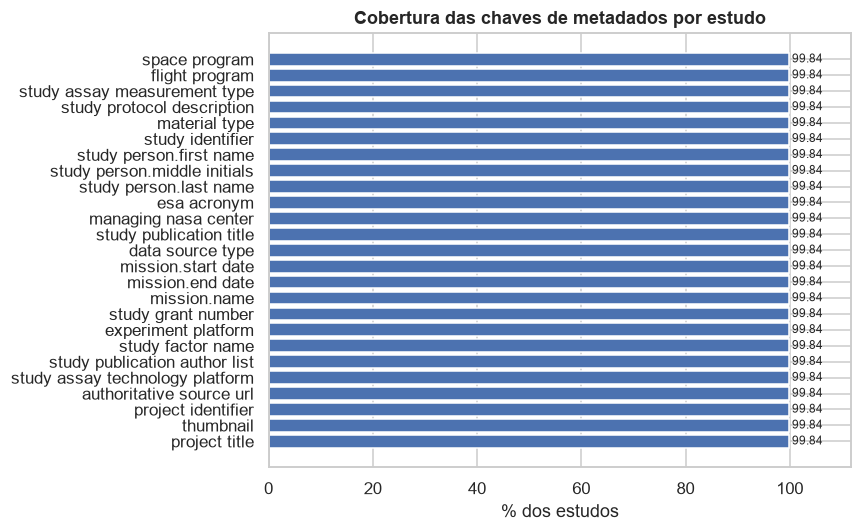

In [18]:
if meta is not None:
    cov = (meta.notna().mean() * 100).sort_values(ascending=False)
    display(cov.round(1).to_frame("% de estudos com a chave"))
    ax = barh(cov.drop(labels=["_error"], errors="ignore"), "Cobertura das chaves de metadados por estudo", top=25, xlabel="% dos estudos")
    plt.tight_layout(); plt.show()

### 3.2 Linha do tempo: quando os estudos foram liberados?

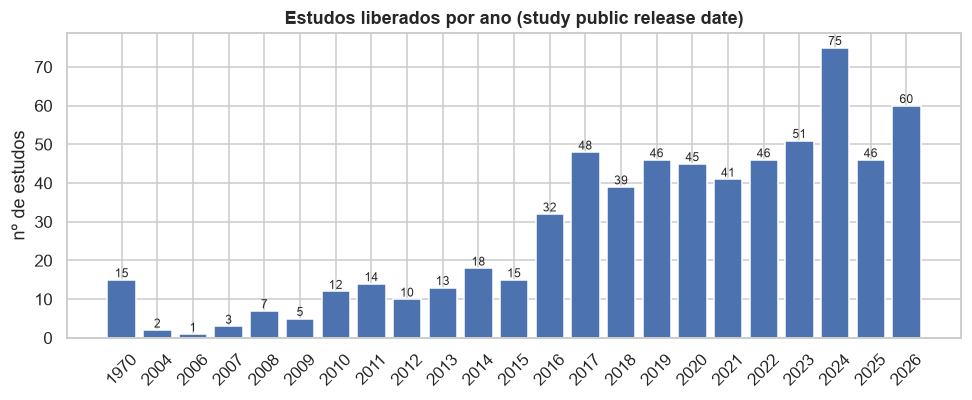

Mais antigo: 1970-01-01 · mais recente: 2026-10-28


In [19]:
COL_REL = pick(meta, r"release date") if meta is not None else None
if COL_REL:
    rel = pd.to_numeric(meta[COL_REL], errors="coerce")
    unit = "ms" if rel.dropna().median() > 1e11 else "s"
    meta["release_date"] = pd.to_datetime(rel, unit=unit, errors="coerce")
    meta["release_year"] = meta["release_date"].dt.year
    per_year = meta["release_year"].value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.bar(per_year.index.astype(int).astype(str), per_year.values, color=sns.color_palette("deep")[0])
    for x, v in zip(range(len(per_year)), per_year.values):
        ax.text(x, v, str(v), ha="center", va="bottom", fontsize=8)
    ax.set_title("Estudos liberados por ano (study public release date)")
    ax.set_ylabel("nº de estudos"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()
    print(f"Mais antigo: {meta.release_date.min():%Y-%m-%d} · mais recente: {meta.release_date.max():%Y-%m-%d}")
else:
    print("Chave de data de liberação não encontrada nos metadados.")

### 3.3 Títulos e descrições (úteis para busca por palavra-chave mais adiante)

In [20]:
COL_TITLE = pick(meta, r"title$") if meta is not None else None
COL_DESC  = pick(meta, r"description") if meta is not None else None
print("coluna de título:", COL_TITLE, "| coluna de descrição:", COL_DESC)
if COL_TITLE:
    display(meta[[COL_TITLE]].dropna().sample(min(8, meta[COL_TITLE].notna().sum()), random_state=1))
    lens = meta[COL_TITLE].dropna().str.len()
    print(f"Tamanho médio do título: {lens.mean():.0f} caracteres")

coluna de título: project title | coluna de descrição: study protocol description


,project title
accession,
OSD-450,
OSD-582,International Space Station Microbial Observatory of Pathogenic Virus Bacteria and Fun...
OSD-615,
OSD-490,
OSD-702,
OSD-613,Rodent Research Reference Mission 2
OSD-810,
OSD-899,


Tamanho médio do título: 24 caracteres


## 4. Ensaios (*assays*): o que foi medido e com qual tecnologia

O nome do ensaio embute a taxonomia: `OSD-174_transcription-profiling_dna-microarray_Agilent` → **tipo de medida** · **tecnologia** · **plataforma**.
Vamos extrair isso e cruzar com o organismo.

In [21]:
assays, mode_assays = query_table("assays", [("study.characteristics.organism", None)])
print("modo usado:", mode_assays, "| shape:", assays.shape)

def parse_assay_name(n):
    parts = str(n).split("_")
    meas = parts[1] if len(parts) > 1 else None
    tech = parts[2] if len(parts) > 2 else None
    plat = "_".join(parts[3:]) if len(parts) > 3 else None
    clean = lambda s: s.replace("-", " ") if isinstance(s, str) else s
    return pd.Series({"measurement": clean(meas), "technology": clean(tech), "platform": plat})

COL_AORG = pick(assays, r"characteristics\.organism$")
assays = pd.concat([assays, assays["id.assay name"].apply(parse_assay_name)], axis=1)
assays["org_group"] = assays[COL_AORG].apply(organism_group) if COL_AORG else "Não informado"

print(f"Estudos: {assays['id.accession'].nunique()} · ensaios: {len(assays)} · "
      f"ensaios/estudo (média): {len(assays) / assays['id.accession'].nunique():.2f}")
display(assays.head(8))

modo usado: v2/query/assays | shape: (1057, 3)
Estudos: 645 · ensaios: 1057 · ensaios/estudo (média): 1.64


,id.accession,id.assay name,study.characteristics.organism,measurement,technology,platform,org_group
0,OSD-1,OSD-1_transcription-profiling_dna-microarray_Affymetrix,Drosophila melanogaster,transcription profiling,dna microarray,Affymetrix,Outros animais
1,OSD-2,OSD-2_transcription-profiling_dna-microarray_agilent,Homo sapiens,transcription profiling,dna microarray,agilent,Humano
2,OSD-3,OSD-3_transcription-profiling_dna-microarray_affymetrix,Drosophila melanogaster,transcription profiling,dna microarray,affymetrix,Outros animais
3,OSD-4,OSD-4_transcription-profiling_dna-microarray_affymetrix,Mus musculus,transcription profiling,dna microarray,affymetrix,Camundongo
4,OSD-5,OSD-5_transcription-profiling_dna-microarray_affymetrix,Homo sapiens,transcription profiling,dna microarray,affymetrix,Humano
5,OSD-6,OSD-6_transcription-profiling_dna-microarray_affymetrix,Rattus norvegicus,transcription profiling,dna microarray,affymetrix,Rato
6,OSD-7,OSD-7_transcription-profiling_dna-microarray_affymetrix,Arabidopsis thaliana,transcription profiling,dna microarray,affymetrix,Planta
7,OSD-8,OSD-8_transcription-profiling_dna-microarray_Agilent,Arabidopsis thaliana,transcription profiling,dna microarray,Agilent,Planta


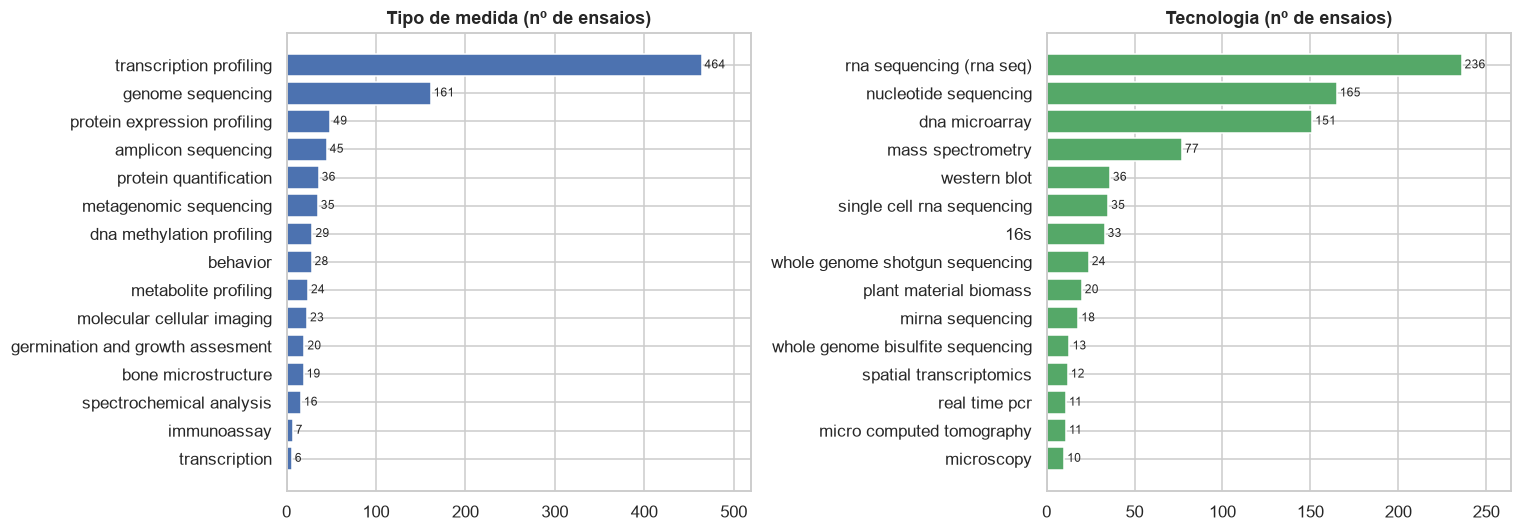

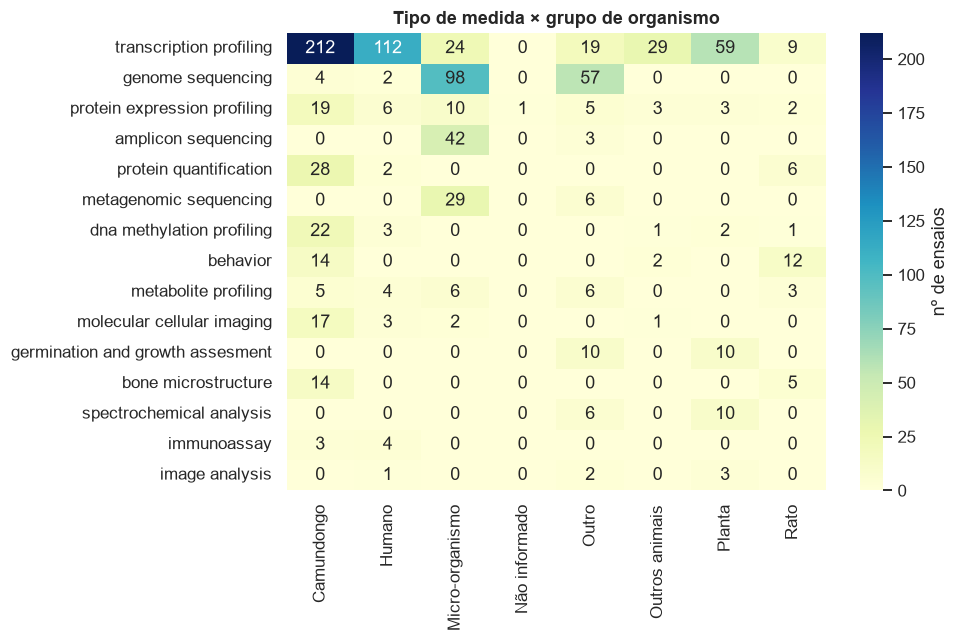

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
barh(assays["measurement"].value_counts(), "Tipo de medida (nº de ensaios)", top=15, ax=axes[0])
barh(assays["technology"].value_counts(), "Tecnologia (nº de ensaios)", top=15, ax=axes[1], color=sns.color_palette("deep")[2])
plt.tight_layout(); plt.show()

ct = pd.crosstab(assays["measurement"], assays["org_group"])
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).head(15).index]
plt.figure(figsize=(9, 6))
sns.heatmap(ct, annot=True, fmt="d", cmap="YlGnBu", cbar_kws={"label": "nº de ensaios"})
plt.title("Tipo de medida × grupo de organismo"); plt.ylabel(""); plt.xlabel("")
plt.tight_layout(); plt.show()

## 5. Amostras (nível mais granular)

Aqui está o coração do EDA: **uma linha por amostra**, com as colunas de `study.characteristics` (descrevem a amostra: organismo, tecido, sexo, idade…) e `study.factor value` (as **variáveis experimentais**: voo espacial, radiação, tempo…).
Usamos o recurso de "soltar o último nível" para trazer todas as colunas dos dois grupos.

In [23]:
t0 = time.time()
SAMPLE_PARAMS = [("study.characteristics", None), ("study.factor value", None)]
samples, mode_samples = query_table("samples", SAMPLE_PARAMS)
if samples.shape[1] <= len(ID_COLS["samples"]) + 1:      # endpoint novo ignorou os seletores de grupo?
    print("⚠️ o endpoint novo devolveu poucas colunas; tentando o legado /v2/query/metadata/ …")
    samples, mode_samples = query_table("samples", SAMPLE_PARAMS, force_legacy=True)
print(f"modo: {mode_samples} · {time.time() - t0:.0f}s")
print(f"shape: {samples.shape[0]:,} amostras × {samples.shape[1]} colunas · "
      f"{samples['id.accession'].nunique()} estudos · memória ≈ {samples.memory_usage(deep=True).sum() / 1e6:.1f} MB")
display(samples.iloc[:5, :10])

modo: v2/query/samples · 41s
shape: 51,369 amostras × 317 colunas · 641 estudos · memória ≈ 533.6 MB


,id.accession,id.assay name,id.sample name,study.characteristics.age,study.characteristics.age at assay,study.characteristics.age at behavioral testing,study.characteristics.age at euthanasia,study.characteristics.age at experiment start,study.characteristics.age at harvest,study.characteristics.age at irradiation
0,OSD-1,OSD-1_transcription-profiling_dna-microarray_Affymetrix,Dmel_OR_wo_FLT_infdw-Bbas_Rep1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,OSD-1,OSD-1_transcription-profiling_dna-microarray_Affymetrix,Dmel_OR_wo_FLT_infdw-Bbas_Rep2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,OSD-1,OSD-1_transcription-profiling_dna-microarray_Affymetrix,Dmel_OR_wo_FLT_infdw-Bbas_Rep3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,OSD-1,OSD-1_transcription-profiling_dna-microarray_Affymetrix,Dmel_OR_wo_FLT_infdw-Ecol_Rep1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,OSD-1,OSD-1_transcription-profiling_dna-microarray_Affymetrix,Dmel_OR_wo_FLT_infdw-Ecol_Rep2,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 5.1 Dicionário de dados (gerado automaticamente)
Para cada coluna: grupo ISA, % preenchida, nº de valores distintos e exemplos. Serve de **referência de formato** para o time.

In [24]:
def data_dictionary(df):
    rows = []
    for c in df.columns:
        s = df[c]
        nn = s.notna().mean() * 100
        top = s.dropna().astype(str).value_counts().head(3).index.tolist()
        rows.append({"coluna": c,
                     "grupo": ".".join(c.split(".")[:2]),
                     "dtype": str(s.dtype),
                     "% preenchida": round(nn, 1),
                     "n_distintos": s.nunique(dropna=True),
                     "exemplos": " | ".join(t[:30] for t in top)})
    return pd.DataFrame(rows)

dd = data_dictionary(samples)
print("Colunas por grupo:")
display(dd.groupby("grupo").agg(n_colunas=("coluna", "size"), preench_media=("% preenchida", "mean")).round(1))
print("\nColunas mais preenchidas:")
display(dd.sort_values("% preenchida", ascending=False).head(25).reset_index(drop=True))

Colunas por grupo:


,n_colunas,preench_media
grupo,,
id.accession,1,100.0
id.assay name,1,100.0
id.sample name,1,100.0
study.characteristics,169,3.1
study.factor value,145,2.2



Colunas mais preenchidas:


,coluna,grupo,dtype,% preenchida,n_distintos,exemplos
0,id.sample name,id.sample name,str,100.0,39761,2 | 22 | 3
1,id.assay name,id.assay name,str,100.0,864,OSD-366_molecular-cellular-ima | OSD-435_echocardiogram_ultraso | OSD-435_echocardiogr...
2,id.accession,id.accession,str,100.0,641,OSD-366 | OSD-734 | OSD-435
3,study.characteristics.organism,study.characteristics,str,100.0,188,Mus musculus | Microbiota | Rattus norvegicus
4,study.characteristics.material type,study.characteristics,str,90.9,255,"Cells, Cultured | Whole Organism | Cells"
5,study.characteristics.sex,study.characteristics,str,54.9,6,Male | Female | male
6,study.characteristics.strain,study.characteristics,str,54.6,387,"C57BL/6J | Fischer 344 | LE, Rat Strain"
7,study.characteristics.animal source,study.characteristics,str,45.8,31,Jackson Laboratory | Taconic Biosciences | Charles River Laboratories
8,study.factor value.spaceflight,study.factor value,str,41.1,28,Space Flight | Ground Control | Vivarium Control
9,study.factor value.ionizing radiation,study.factor value,str,40.2,33,sham-irradiated | mixed radiation field | non-irradiated


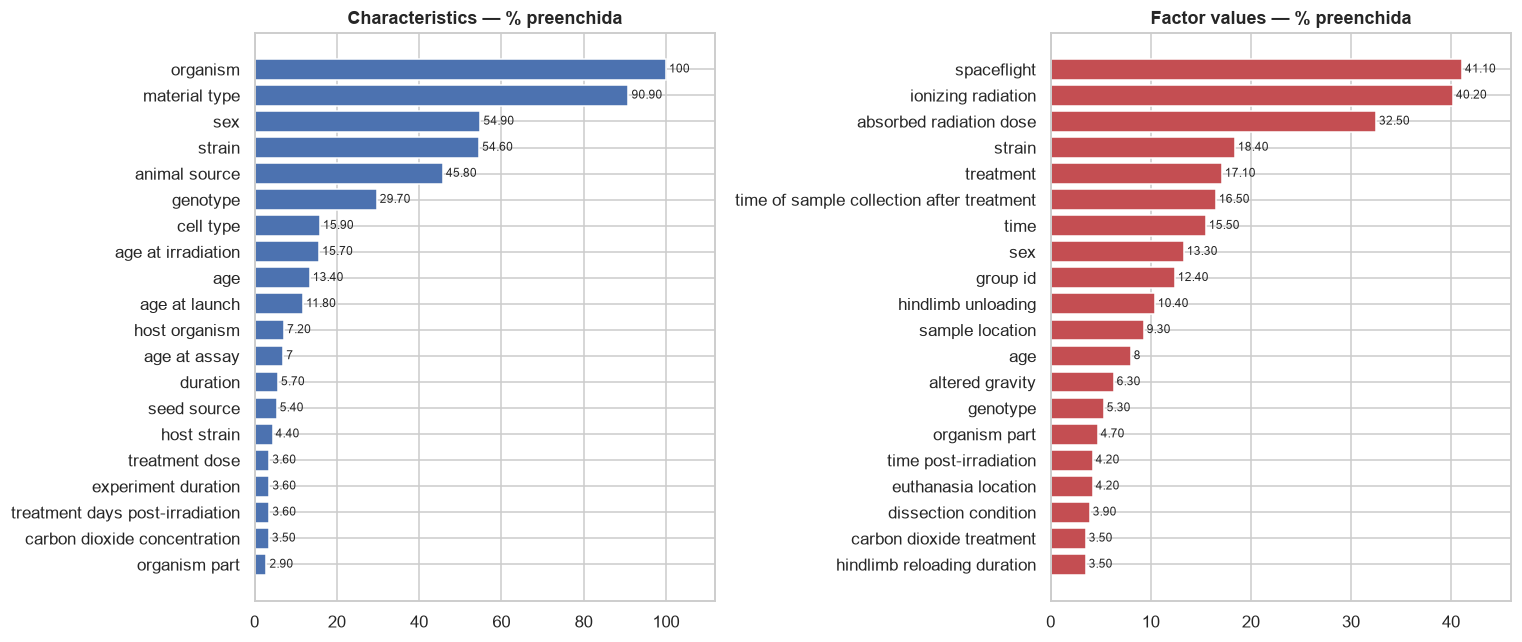

In [26]:
fc = dd[dd["coluna"].str.startswith("study.factor value")].sort_values("% preenchida", ascending=False)
cc = dd[dd["coluna"].str.startswith("study.characteristics")].sort_values("% preenchida", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
barh(cc.set_index("coluna")["% preenchida"].rename(lambda s: s.replace("study.characteristics.", "")), "Characteristics — % preenchida", top=20, ax=axes[0])
barh(fc.set_index("coluna")["% preenchida"].rename(lambda s: s.replace("study.factor value.", "")), "Factor values — % preenchida", top=20, ax=axes[1], color=sns.color_palette("deep")[3])
plt.tight_layout(); plt.show()

### 5.2 Organismos

organismo: study.characteristics.organism | tecido (material type): study.characteristics.material type | spaceflight: study.factor value.spaceflight


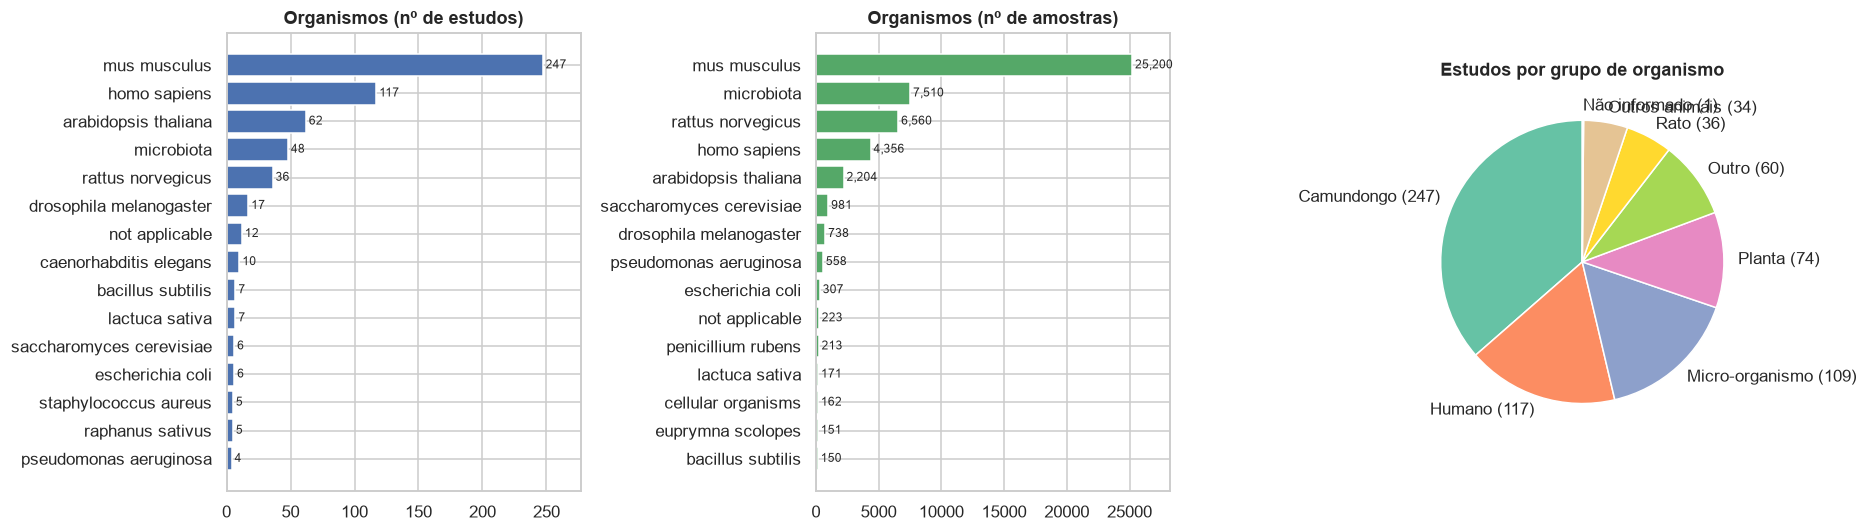

In [27]:
COL_ORG    = pick(samples, r"characteristics\.organism$")
COL_TISSUE = pick(samples, r"characteristics\.material type$")
COL_SF     = pick(samples, r"factor value\.spaceflight$")
print("organismo:", COL_ORG, "| tecido (material type):", COL_TISSUE, "| spaceflight:", COL_SF)

samples["organism_norm"] = samples[COL_ORG].astype(str).str.strip().str.lower() if COL_ORG else "não informado"
samples["org_group"]     = samples["organism_norm"].apply(organism_group)

by_ds = samples.drop_duplicates(["id.accession", "organism_norm"])
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
barh(by_ds["organism_norm"].value_counts(), "Organismos (nº de estudos)", top=15, ax=axes[0])
barh(samples["organism_norm"].value_counts(), "Organismos (nº de amostras)", top=15, ax=axes[1], color=sns.color_palette("deep")[2])
grp = samples.groupby("org_group")["id.accession"].nunique().sort_values(ascending=False)
axes[2].pie(grp.values, labels=[f"{k} ({v})" for k, v in grp.items()], startangle=90,
            colors=sns.color_palette("Set2"), wedgeprops={"edgecolor": "white"})
axes[2].set_title("Estudos por grupo de organismo")
plt.tight_layout(); plt.show()

### 5.3 Tecidos / tipo de material

90.9% das amostras têm 'material type' · 226 valores distintos


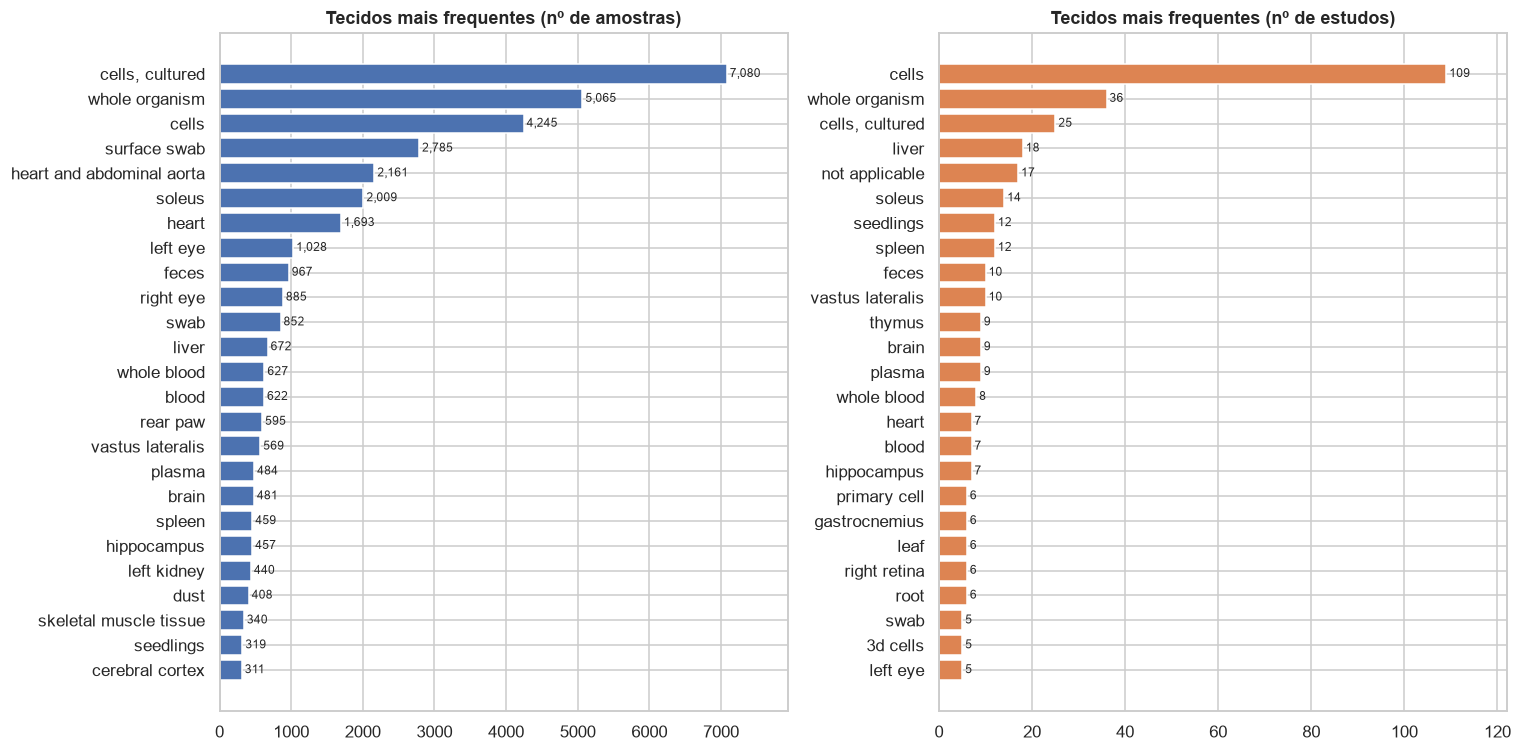

In [28]:
if COL_TISSUE:
    samples["tissue_norm"] = samples[COL_TISSUE].astype(str).str.strip().str.lower().replace({"nan": np.nan})
    tt = samples.dropna(subset=["tissue_norm"])
    print(f"{tt.shape[0] / len(samples) * 100:.1f}% das amostras têm 'material type' · {tt['tissue_norm'].nunique()} valores distintos")
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    barh(tt["tissue_norm"].value_counts(), "Tecidos mais frequentes (nº de amostras)", top=25, ax=axes[0])
    barh(tt.drop_duplicates(["id.accession", "tissue_norm"])["tissue_norm"].value_counts(),
         "Tecidos mais frequentes (nº de estudos)", top=25, ax=axes[1], color=sns.color_palette("deep")[1])
    plt.tight_layout(); plt.show()
else:
    samples["tissue_norm"] = np.nan
    print("Coluna 'material type' não encontrada.")

### 5.4 Fatores experimentais (*factor values*) — as variáveis que os pesquisadores manipularam
Quantos estudos usam cada fator e quais valores assumem.

145 fatores distintos


,fator,n_estudos,n_amostras,n_valores,valores mais comuns
0,spaceflight,345,21105,22,space flight | ground control | vivarium control | not applicable
1,ionizing radiation,120,20629,27,sham-irradiated | mixed radiation field | cesium-137 gamma radiatio | non-irradiated
2,treatment,87,8765,198,normal chow | intact | saline injection | superoxide dismutase mimi
3,time,76,7948,217,9 {month} | 0.5 {month} | 3 {month} | t28
4,genotype,59,2740,73,wild type | pgm-1 | nrf2ko | p21-null
5,altered gravity,56,3221,77,1g controls | 0g with hindlimb unloadin | 0.4g with partial weight | 1g on earth
6,age,55,4092,26,3 {month} | 9 {month} | 8 {month} | 29 {week}
7,microgravity simulation,46,1020,30,ug by rwv | 1g on earth | 1g by rwv | not applicable
8,absorbed radiation dose,46,16707,67,0 {gray} | 1 {gray} | 0.5 {gray} | 0.3 {gray}
9,hindlimb unloading,39,5338,19,hindlimb unloaded | normally loaded control | normal loading control | baseline


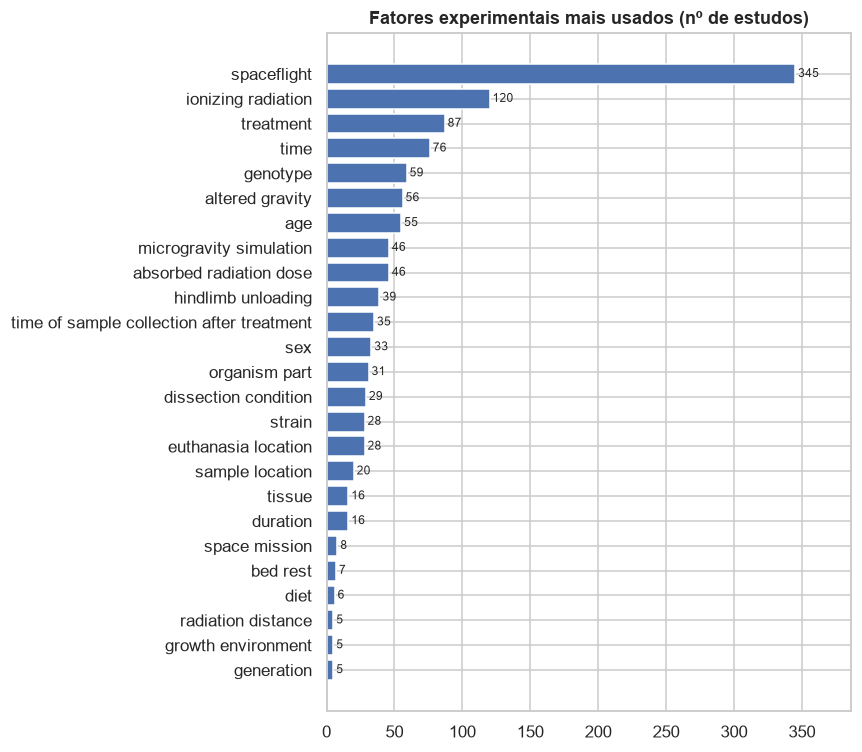

In [29]:
factor_cols = pick_all(samples, r"^study\.factor value\.")
fdf = []
for c in factor_cols:
    sub = samples[samples[c].notna()]
    fdf.append({"fator": c.replace("study.factor value.", ""),
                "n_estudos": sub["id.accession"].nunique(),
                "n_amostras": len(sub),
                "n_valores": sub[c].astype(str).str.lower().nunique(),
                "valores mais comuns": " | ".join(sub[c].astype(str).str.lower().value_counts().head(4).index.str[:25])})
fdf = pd.DataFrame(fdf).sort_values("n_estudos", ascending=False).reset_index(drop=True)
print(f"{len(fdf)} fatores distintos")
display(fdf.head(30))
barh(fdf.set_index("fator")["n_estudos"], "Fatores experimentais mais usados (nº de estudos)", top=25, figsize=(8, 7))
plt.tight_layout(); plt.show()

#### Spaceflight × controle
O fator `spaceflight` é o eixo central dos estudos; normalizamos os rótulos (`Space Flight`, `In-flight`, `Ground Control`, `Basal`, `Vivarium`…).

In [30]:
def norm_sf(v):
    v = str(v).lower()
    if v in ("nan", "none", ""):                                              return np.nan
    if re.search(r"ground|control|basal|vivarium|habitat|synchronous|cage", v): return "Controle (solo/basal)"
    if re.search(r"flight|iss|orbit|shuttle|space|post|pre", v):                return "Voo / pré-pós voo"
    return "Outro"

if COL_SF:
    samples["spaceflight_norm"] = samples[COL_SF].apply(norm_sf)
    sf = samples["spaceflight_norm"].value_counts(dropna=True)
    print(f"{samples['spaceflight_norm'].notna().mean() * 100:.1f}% das amostras têm o fator 'spaceflight'")
    display(sf.to_frame("n_amostras"))
    display(samples.dropna(subset=["spaceflight_norm"]).groupby(["org_group", "spaceflight_norm"]).size().unstack(fill_value=0))
else:
    samples["spaceflight_norm"] = np.nan
    print("Fator 'spaceflight' não encontrado como coluna dedicada.")

41.1% das amostras têm o fator 'spaceflight'


,n_amostras
spaceflight_norm,
Voo / pré-pós voo,12239
Controle (solo/basal),7947
Outro,919


spaceflight_norm,Controle (solo/basal),Outro,Voo / pré-pós voo
org_group,,,
Camundongo,5136,100,3411
Humano,210,15,1119
Micro-organismo,1556,544,5786
Não informado,0,2,0
Outro,93,182,389
Outros animais,237,16,410
Planta,550,0,985
Rato,165,60,139


### 5.5 Qualidade dos dados: valores faltantes e inconsistências

Colunas 100% vazias: 0 · colunas >90% vazias: 294 de 317


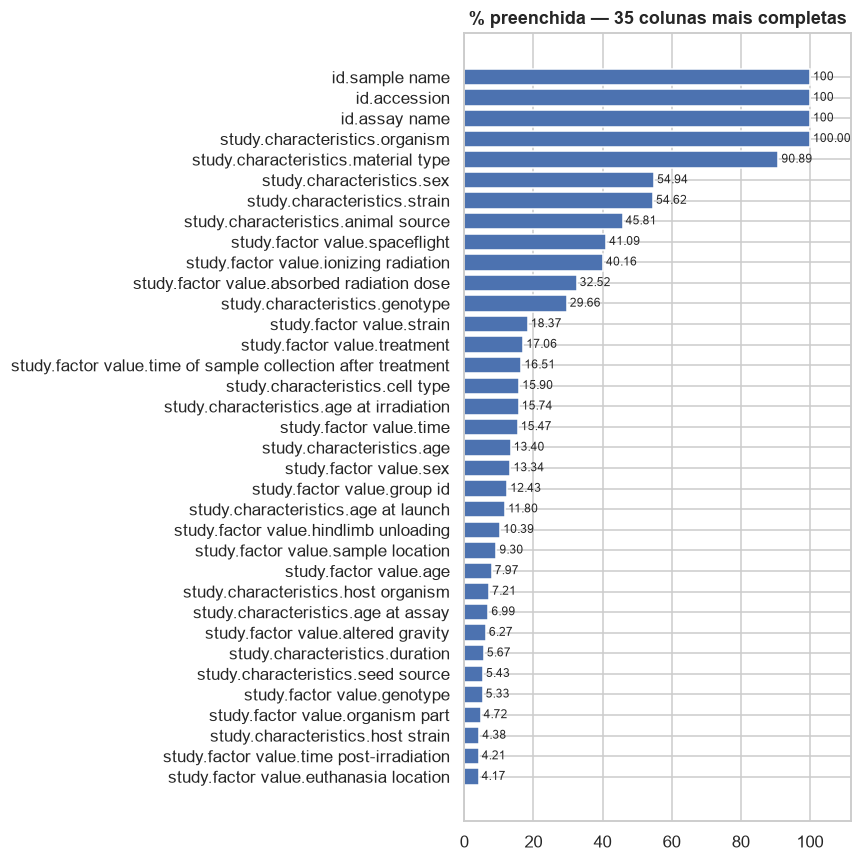


Organismo: 188 grafias → 188 após lower() (a API é case-insensitive nos filtros, as tabelas não).


In [31]:
miss = (samples.isna().mean() * 100).sort_values(ascending=False)
miss = miss[~miss.index.isin(["organism_norm", "org_group", "tissue_norm", "spaceflight_norm"])]
print(f"Colunas 100% vazias: {(miss == 100).sum()} · colunas >90% vazias: {(miss > 90).sum()} de {len(miss)}")
top_cols = (100 - miss).sort_values(ascending=False).head(35)
barh(top_cols, "% preenchida — 35 colunas mais completas", top=35, figsize=(8, 8))
plt.tight_layout(); plt.show()

# inconsistência de caixa/grafia
if COL_ORG:
    raw_variants = samples[COL_ORG].dropna().astype(str).str.strip()
    collapsed = raw_variants.str.lower().nunique()
    print(f"\nOrganismo: {raw_variants.nunique()} grafias → {collapsed} após lower() (a API é case-insensitive nos filtros, as tabelas não).")

## 6. Arquivos e **dados quantitativos** disponíveis

Para um app, o que importa é saber que **tabelas numéricas prontas** existem. O campo `file.datatype` classifica os arquivos associados a cada estudo (`unnormalized counts`, `normalized counts`, `differential expression`, `pca`, …).

### 6.1 Tipos de dado (`file.datatype`) por estudo

modo: v2/query/datasets · 28 tipos de dado · 645 estudos


,n_estudos
file.datatype,
raw reads,297
differential expression contrasts,242
differential expression table,242
sample table,240
alignment,203
trimmed reads,194
raw multiqc data,188
unnormalized counts,183
unnormalized counts - supplementary,179


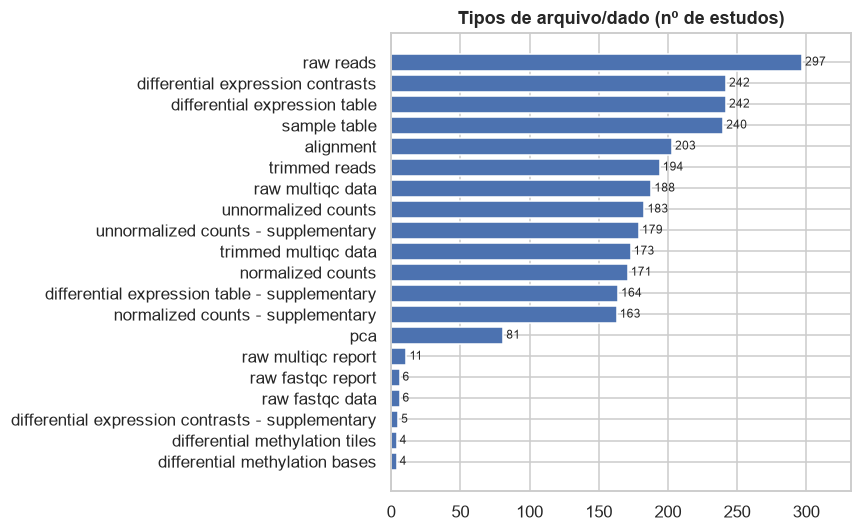

In [32]:
ft = None
try:
    ft, mode_ft = query_table("datasets", [("file.datatype", None)])
    COL_DT  = pick(ft, r"file\.data ?type")
    COL_FA  = pick(ft, r"^id\.accession$") or "id.accession"
    ft[COL_DT] = ft[COL_DT].astype(str).str.lower().str.strip().replace({"nan": np.nan})
    dt_counts = ft.dropna(subset=[COL_DT]).groupby(COL_DT)[COL_FA].nunique().sort_values(ascending=False)
    print(f"modo: {mode_ft} · {len(dt_counts)} tipos de dado · {ft[COL_FA].nunique()} estudos")
    display(dt_counts.to_frame("n_estudos"))
    barh(dt_counts, "Tipos de arquivo/dado (nº de estudos)", top=20)
    plt.tight_layout(); plt.show()
except Exception as e:
    print("⚠️ Não foi possível obter file.datatype:", str(e)[:200])
    COL_DT = COL_FA = None

### 6.2 Inventário de arquivos (amostra de estudos)
Lista os arquivos reais (via `/v2/dataset/<OSD>/files/`) dos primeiros `N_DATASETS_FILE_INVENTORY` estudos **mais relevantes** (a lista de relevância é montada na seção 7 — esta célula será executada de novo lá com o ranking; por ora usamos os primeiros estudos como demonstração).

691 arquivos em 30 estudos


,n_arquivos
category,
Reads/alinhamentos brutos,299
Tabelas / planilhas (outros),117
Compactados (outros),102
Outros,39
Tabela de amostras / contrastes,37
Metadados ISA,30
Contagens normalizadas,29
PCA,12
QC (MultiQC/FastQC),12


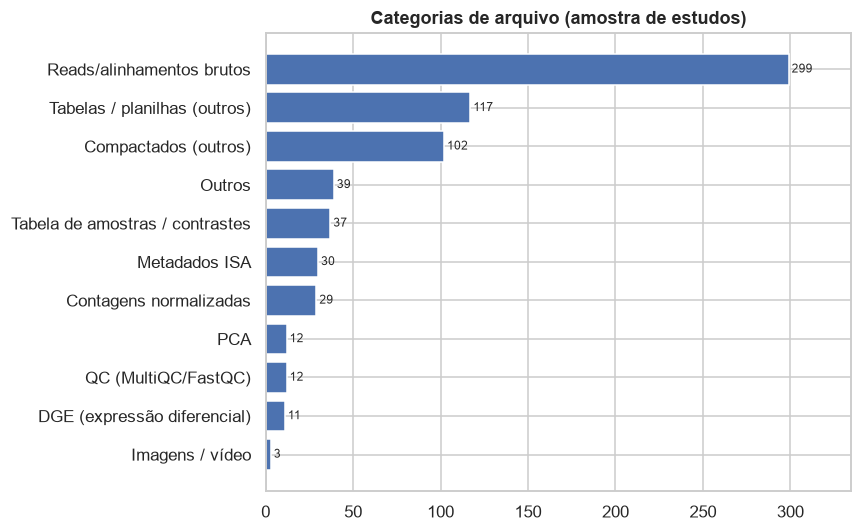

In [33]:
FILE_RULES = [
    ("DGE (expressão diferencial)",     r"differential_expression|_dge|dge_"),
    ("Contagens não normalizadas",      r"unnormalized"),
    ("Contagens normalizadas",          r"normalized"),
    ("PCA",                             r"pca"),
    ("Tabela de amostras / contrastes", r"sampletable|contrasts|runsheet"),
    ("QC (MultiQC/FastQC)",             r"multiqc|fastqc"),
    ("Reads/alinhamentos brutos",       r"\.(fastq|fq|bam|cram|sra|cel|idat|raw)(\.|$)"),
    ("Metadados ISA",                   r"isa\.zip|isa-tab|^i_|^s_|^a_"),
    ("Imagens / vídeo",                 r"\.(png|jpg|jpeg|tif|tiff|mp4|avi|svg)$"),
    ("Tabelas / planilhas (outros)",    r"\.(csv|tsv|xlsx|xls|txt)$"),
    ("Compactados (outros)",            r"\.(zip|tar|gz|tgz|7z)"),
]
def classify_file(name):
    n = name.lower()
    for label, rx in FILE_RULES:
        if re.search(rx, n):
            return label
    return "Outros"

def list_files(acc):
    try:
        j = json.loads(http_get(build_url(f"/v2/dataset/{acc}/files/")))
        files = j.get(acc, {}).get("files", {})
        return [{"accession": acc, "file": n, "url": v.get("URL"), "category": classify_file(n)} for n, v in files.items()]
    except Exception:
        return []

def file_inventory(accs):
    rows = []
    with ThreadPoolExecutor(max_workers=N_THREADS) as ex:
        for r in ex.map(list_files, accs):
            rows.extend(r)
    return pd.DataFrame(rows)

inv_demo = file_inventory(df_ds["accession"].head(N_DATASETS_FILE_INVENTORY).tolist())
print(f"{len(inv_demo):,} arquivos em {inv_demo['accession'].nunique()} estudos")
if len(inv_demo):
    cats = inv_demo["category"].value_counts()
    display(cats.to_frame("n_arquivos"))
    barh(cats, "Categorias de arquivo (amostra de estudos)", top=12)
    plt.tight_layout(); plt.show()

## 7. Relevância para o projeto: *hazards* × sistemas do corpo × indicadores

Aqui conectamos o repositório ao desafio. A NASA HRP define **5 hazards** do voo espacial; cada um afeta sistemas do corpo e, portanto, indicadores que o app pode monitorar. O plano:

1. **Classificar cada amostra/estudo** por *hazard* (a partir dos fatores experimentais) e por **sistema fisiológico** (a partir do tecido) — com regex heurísticos, editáveis.
2. Montar a **matriz sistema × hazard** (onde há evidência no OSDR?). Isso alimenta diretamente a ideia do **corpo humano clicável** do desafio.
3. Isolar o **foco humano** e as amostras **não invasivas** (sangue, urina, saliva, cabelo… coletáveis em órbita).
4. Calcular um **score de relevância** por estudo e escolher o que extrair.
5. Procurar **indicadores/biomarcadores** do desafio (glicose, sono, estresse, inflamação…) nos metadados.

> Tudo aqui é **heurística baseada em texto** — serve para priorizar leitura, não como classificação definitiva. Revise os 20–30 estudos do topo manualmente.

### 7.1 Taxonomia (editável)

In [34]:
# --- 5 hazards da NASA HRP (regex aplicados ao texto dos fatores experimentais) ---
HAZARDS = {
    "Radiação espacial":
        r"radiat|irradiat|\bgy\b|\bcgy\b|proton|heavy ion|iron ion|\bhze\b|gamma|x-?ray|cosmic",
    "Gravidade (micro/hiper/simulada)":
        r"spaceflight|space flight|microgravity|hindlimb|unloading|clinostat|clinorotat|rotating wall|\brwv\b|"
        r"random positioning|\brpm\b|centrifug|hypergravity|artificial gravity|weightless|\bflight\b|parabolic",
    "Isolamento e confinamento":
        r"bed ?rest|\bhdbr\b|head-?down|hi-?seas|mars-?500|antarctic|confine|social isolation|isolation (housing|stress)|"
        r"isolated housing|sleep (loss|deprivation|restriction)|psychosocial|social stress|\banalog\b|analogue mission",
    "Ambiente hostil/fechado":
        r"microbio|bacteri|atmospher|\bco2\b|carbon dioxide|hypox|hyperox|humidity|temperature|contaminat|"
        r"closed environment|ventilat|particulate|dust",
    "Distância da Terra / duração (proxy)":
        r"duration|mission length|days? in flight|long-?duration|time ?point|post-?flight|pre-?flight|recovery|re-?adapt",
}
# hazards que também procuramos no TÍTULO do estudo (regex mais estritos para evitar ruído)
TITLE_HAZARDS = ["Radiação espacial", "Gravidade (micro/hiper/simulada)", "Isolamento e confinamento"]

# --- sistemas do corpo (regex aplicados ao tecido / parte do organismo) ---
SYSTEMS = {
    "Musculoesquelético":     r"bone|femur|tibia|humerus|vertebra|calvaria|lumbar|muscle|soleus|gastrocnemius|quadriceps|tibialis|extensor digitorum|\bedl\b|skeletal|cartilage|tendon",
    "Cardiovascular":         r"heart|cardiac|aorta|artery|carotid|vascular|endotheli|myocard|ventric|atri(um|a)",
    "Imune / hematológico":   r"blood|plasma|serum|pbmc|leukocyte|lymph|spleen|thymus|marrow|monocyte|t cell|b cell|macrophage|neutrophil|immune",
    "Renal / urinário":       r"kidney|renal|urine|bladder|urinary",
    "Hepático / metabólico":  r"liver|hepat|adipose|\bfat\b|pancrea|islet",
    "Visão (olho/retina)":    r"retina|\beye\b|optic|cornea|\blens\b|choroid",
    "Neurológico":            r"brain|cortex|hippocamp|cerebell|hypothalam|spinal|dorsal root|cochlea|vestibul|neuro|striatum",
    "Pele / cabelo":          r"skin|dermal|epiderm|\bhair\b|keratinocyte",
    "Gastrointestinal":       r"intestin|colon|\bgut\b|fecal|feces|stool|cecum|jejun|ileum|duoden|stomach",
    "Endócrino / reprodutivo": r"testis|testes|ovary|ovaries|uter|thyroid|adrenal|pituitary",
    "Respiratório":           r"lung|trachea|bronch",
}

# amostras que seriam coletáveis em um astronauta sem procedimento invasivo
NONINVASIVE = r"blood|plasma|serum|pbmc|urine|saliva|\bhair\b|feces|fecal|stool|skin|sweat|breath"

# --- indicadores / biomarcadores do desafio e proxies moleculares ---
BIOMARKERS = {
    "Glicose / metabolismo":        r"glucose|glycem|insulin|hba1c|metabol",
    "Cardiovascular (PA/FC)":       r"blood pressure|heart rate|cardiac|\becg\b|vascular|endotheli|troponin|\bbnp\b",
    "Imunidade / inflamação":       r"cytokine|interleukin|\bil-?6\b|\bcrp\b|c-reactive|inflamm|immune|leukocyte|lymphocyte|nk cell",
    "Estresse / humor / sono":      r"cortisol|stress|sleep|circadian|mood|depress|anxiety|melatonin|behavio",
    "Osso / músculo":               r"bone density|\bbmd\b|osteo|calcium|vitamin d|sarcopenia|atrophy|muscle mass|telopeptide|p1np",
    "Hematologia":                  r"hemoglobin|hematocrit|erythro|anemia|platelet|complete blood count|\bcbc\b|red blood",
    "Dano de DNA / radiação":       r"dna damage|telomere|h2ax|chromosom|mutation|oxidative",
    "Temperatura / termorregulação": r"temperature|thermo|core body",
    "Nutrição":                     r"nutri|\bdiet|vitamin|ferritin|folate|\bfood",
}
print(f"{len(HAZARDS)} hazards · {len(SYSTEMS)} sistemas · {len(BIOMARKERS)} famílias de biomarcadores")

5 hazards · 11 sistemas · 9 famílias de biomarcadores


### 7.2 Classificação em nível de amostra

In [35]:
def build_text(df, cols, with_names=True):
    """Concatena (nome=valor) das colunas em um texto minúsculo por linha."""
    txt = pd.Series("", index=df.index, dtype="object")
    for c in cols:
        v = df[c]
        name = c.split(".")[-1]
        piece = (" | " + name + "=" + v.astype(str)) if with_names else (" | " + v.astype(str))
        txt = txt + pd.Series(np.where(v.notna(), piece, ""), index=df.index)
    return txt.str.lower()

factor_cols = pick_all(samples, r"^study\.factor value\.")
tissue_cols = pick_all(samples, r"(material type|organism part|tissue|anatomical|cell type|sample type|body site)$")
print(f"{len(factor_cols)} colunas de fator · {len(tissue_cols)} colunas de tecido/parte")

factor_text = build_text(samples, factor_cols, with_names=True)
tissue_text = build_text(samples, tissue_cols, with_names=False)

HZ = {k: f"H: {k}" for k in HAZARDS}
SY = {k: f"S: {k}" for k in SYSTEMS}
for k, rx in HAZARDS.items():
    samples[HZ[k]] = factor_text.str.contains(rx, regex=True, na=False)
for k, rx in SYSTEMS.items():
    samples[SY[k]] = tissue_text.str.contains(rx, regex=True, na=False)
samples["noninvasive"] = tissue_text.str.contains(NONINVASIVE, regex=True, na=False)

summary = pd.DataFrame({
    "% das amostras": {**{k: samples[v].mean() * 100 for k, v in HZ.items()},
                       **{k: samples[v].mean() * 100 for k, v in SY.items()},
                       "Amostra não invasiva": samples["noninvasive"].mean() * 100}})
summary.insert(0, "tipo", ["hazard"] * len(HZ) + ["sistema"] * len(SY) + ["coleta"])
display(summary.round(1))

145 colunas de fator · 8 colunas de tecido/parte


,tipo,% das amostras
Radiação espacial,hazard,40.3
Gravidade (micro/hiper/simulada),hazard,55.2
Isolamento e confinamento,hazard,2.4
Ambiente hostil/fechado,hazard,5.9
Distância da Terra / duração (proxy),hazard,8.8
Musculoesquelético,sistema,11.1
Cardiovascular,sistema,8.2
Imune / hematológico,sistema,7.0
Renal / urinário,sistema,1.7
Hepático / metabólico,sistema,2.8


### 7.3 Tabela em nível de **estudo** (uma linha por OSD)
Agrega as amostras e acrescenta: título/ano (se `meta` existir), sinais de hazard no título e a disponibilidade de dados quantitativos (`file.datatype`).

In [36]:
g = samples.groupby("id.accession")
ds = pd.DataFrame({
    "n_samples":   g.size(),
    "n_assays":    g["id.assay name"].nunique(),
    "org_group":   g["org_group"].agg(lambda s: s.mode().iat[0]),
    "organism":    g["organism_norm"].agg(lambda s: "; ".join(sorted(set(s.dropna().astype(str))))[:70]),
    "tissues":     g["tissue_norm"].agg(lambda s: ", ".join(s.dropna().value_counts().head(3).index)),
    "noninvasive": g["noninvasive"].max(),
})
for c in list(HZ.values()) + list(SY.values()):
    ds[c] = g[c].max()

# título / ano
ds["title"], ds["release_year"] = "", np.nan
if meta is not None:
    if COL_TITLE:
        ds["title"] = meta[COL_TITLE].reindex(ds.index).fillna("").astype(str).str.slice(0, 140)
    if "release_year" in meta.columns:
        ds["release_year"] = meta["release_year"].reindex(ds.index)

# hazards inferidos do título (só os 3 mais "limpos")
title_l = ds["title"].str.lower()
for k in TITLE_HAZARDS:
    ds[HZ[k]] = ds[HZ[k]] | title_l.str.contains(HAZARDS[k], regex=True, na=False)

# dados quantitativos disponíveis (file.datatype)
def accs_with(rx):
    if ft is None or COL_DT is None:
        return set()
    return set(ft.loc[ft[COL_DT].fillna("").str.contains(rx, regex=True), COL_FA])

ds["has_counts"] = ds.index.isin(accs_with(r"counts"))
ds["has_dge"]    = ds.index.isin(accs_with(r"differential"))
ds["has_pca"]    = ds.index.isin(accs_with(r"pca"))
ds["has_quant"]  = ds["has_counts"] | ds["has_dge"]

# tipos de medida por estudo
ds["measurements"] = assays.groupby("id.accession")["measurement"].agg(lambda s: ", ".join(sorted(set(s.dropna())))[:80]).reindex(ds.index).fillna("")

print(f"Tabela de estudos: {ds.shape[0]} × {ds.shape[1]}")
display(ds[["n_samples", "org_group", "tissues", "noninvasive", "has_quant", "title"]].head(10))

Tabela de estudos: 641 × 29


,n_samples,org_group,tissues,noninvasive,has_quant,title
id.accession,,,,,,
OSD-1,18,Outros animais,whole organism,False,True,Drosophila as a model of immune function in conditions of altered gravitational force
OSD-100,24,Camundongo,left eye,False,True,Rodent Research 1
OSD-1000,18,Humano,"cells, cultured",False,False,
OSD-1005,23,Humano,"cells, cultured",False,False,
OSD-1008,10,Humano,"cells, cultured",False,False,
OSD-101,52,Camundongo,"left gastrocnemius, not applicable",False,True,Rodent Research 1
OSD-1012,92,Humano,blood,True,False,
OSD-1014,40,Humano,"cells, cultured",False,False,
OSD-1015,12,Humano,"cells, cultured",False,False,


### 7.4 Matriz **sistema × hazard** — onde o OSDR tem evidência?
Cada célula = nº de **estudos** que combinam aquele sistema (tecido) com aquele hazard (fator). É a base do mapa de calor/corpo clicável do app.

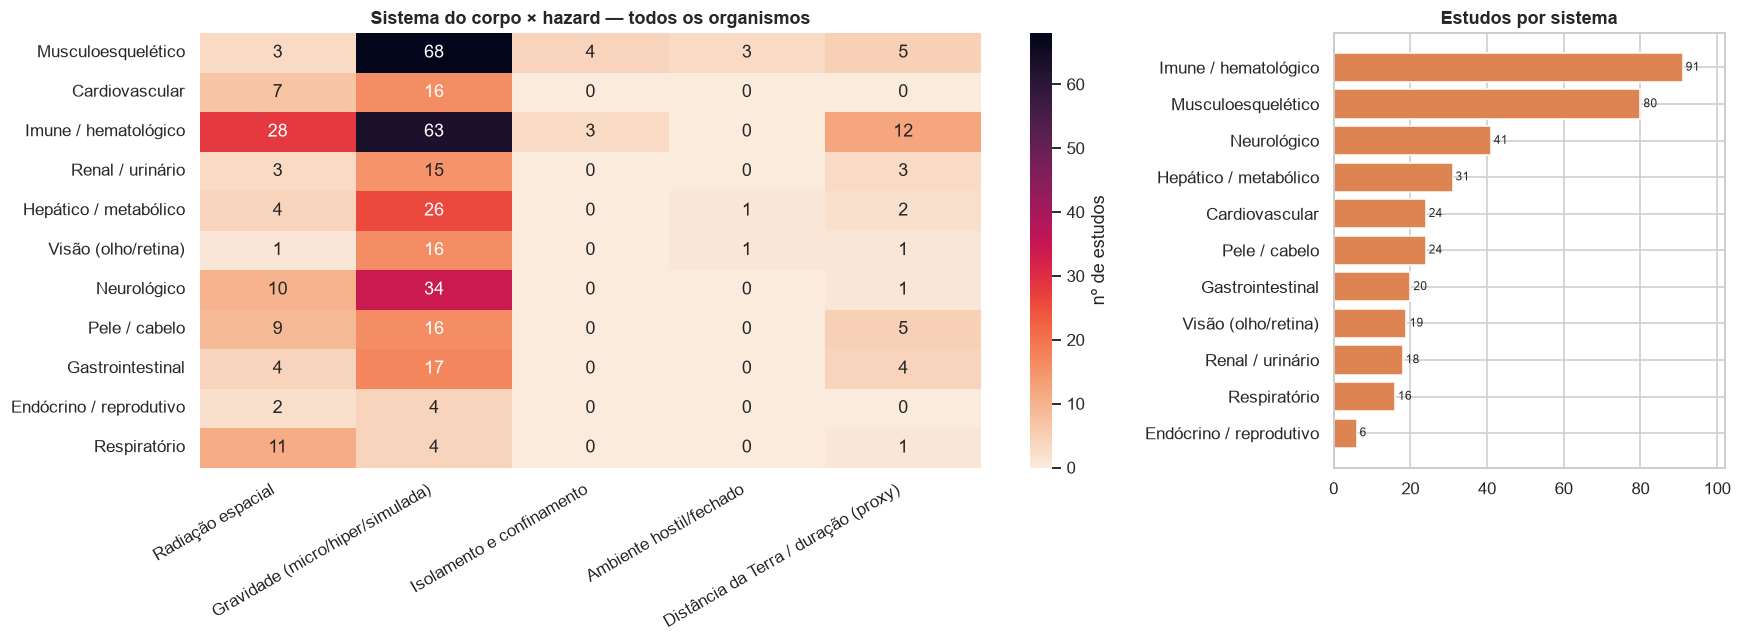

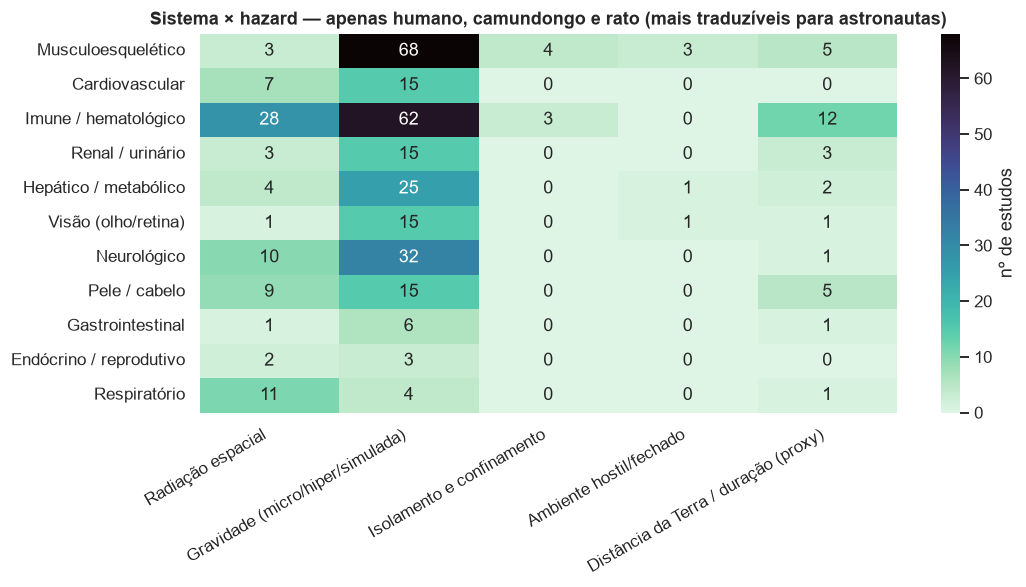

In [37]:
def matrix(sub):
    S = sub[list(SY.values())].astype(int)
    H = sub[list(HZ.values())].astype(int)
    M = S.T.dot(H)
    M.index = [i.replace("S: ", "") for i in M.index]
    M.columns = [c.replace("H: ", "") for c in M.columns]
    return M

M_all = matrix(ds)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [3, 1.2]})
sns.heatmap(M_all, annot=True, fmt="d", cmap="rocket_r", ax=axes[0], cbar_kws={"label": "nº de estudos"})
axes[0].set_title("Sistema do corpo × hazard — todos os organismos")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha="right")
sys_tot = pd.Series({k.replace("S: ", ""): int(ds[k].sum()) for k in SY.values()})
barh(sys_tot, "Estudos por sistema", top=12, ax=axes[1], color=sns.color_palette("deep")[1])
plt.tight_layout(); plt.show()

ds_mamm = ds[ds["org_group"].isin(["Humano", "Camundongo", "Rato"])]
M_m = matrix(ds_mamm)
plt.figure(figsize=(10, 5.5))
sns.heatmap(M_m, annot=True, fmt="d", cmap="mako_r", cbar_kws={"label": "nº de estudos"})
plt.title("Sistema × hazard — apenas humano, camundongo e rato (mais traduzíveis para astronautas)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

In [38]:
# visão interativa (opcional): organismo → sistema → nº de estudos
try:
    import plotly.express as px
    rows = []
    for k, col in SY.items():
        sub = ds[ds[col]]
        for og, n in sub["org_group"].value_counts().items():
            rows.append({"organismo": og, "sistema": k, "estudos": int(n)})
    sb = pd.DataFrame(rows)
    fig = px.sunburst(sb, path=["organismo", "sistema"], values="estudos",
                      title="Organismo → sistema do corpo (nº de estudos; um estudo pode aparecer em mais de um sistema)")
    fig.update_layout(height=560)
    fig.show()
except Exception as e:
    print("plotly indisponível — pulando a visão interativa:", str(e)[:80])

plotly indisponível — pulando a visão interativa: No module named 'plotly'


### 7.5 Foco **humano** e amostras **não invasivas**
Estudos com *Homo sapiens* são a ponte mais direta com astronautas; amostras como sangue, urina, saliva e cabelo são as que realmente podem ser coletadas a bordo.

Estudos humanos: 114 (17.8% dos estudos) · amostras humanas: 4,354


,n_samples,n_assays,tissues,measurements,has_quant,release_year,title
id.accession,,,,,,,
OSD-51,340,1,skeletal muscle tissue,transcription profiling,False,2010.0,LBNP Treadmill and Resistive Exercises during Long-term Bed Rest
OSD-354,230,1,vastus lateralis,transcription profiling,False,2020.0,
OSD-571,140,5,plasma,"genome sequencing, metabolite profiling, protein expression profiling, transcrip",False,2024.0,
OSD-73,134,1,cells,transcription profiling,False,2014.0,
OSD-530,128,2,plasma,transcription profiling,False,2022.0,
OSD-569,117,5,"whole blood, rbc pellet","complete blood count, genome sequencing, targeted genome sequencing, transcripti",False,2024.0,
OSD-574,113,3,"skin biopsy, swab, not applicable","metagenomic sequencing, metatranscriptome sequencing assay, transcription profil",False,2024.0,
OSD-575,111,4,serum,"analytical chemistry, immunoassay",False,2024.0,
OSD-317,102,1,cells,dna methylation profiling,False,2017.0,


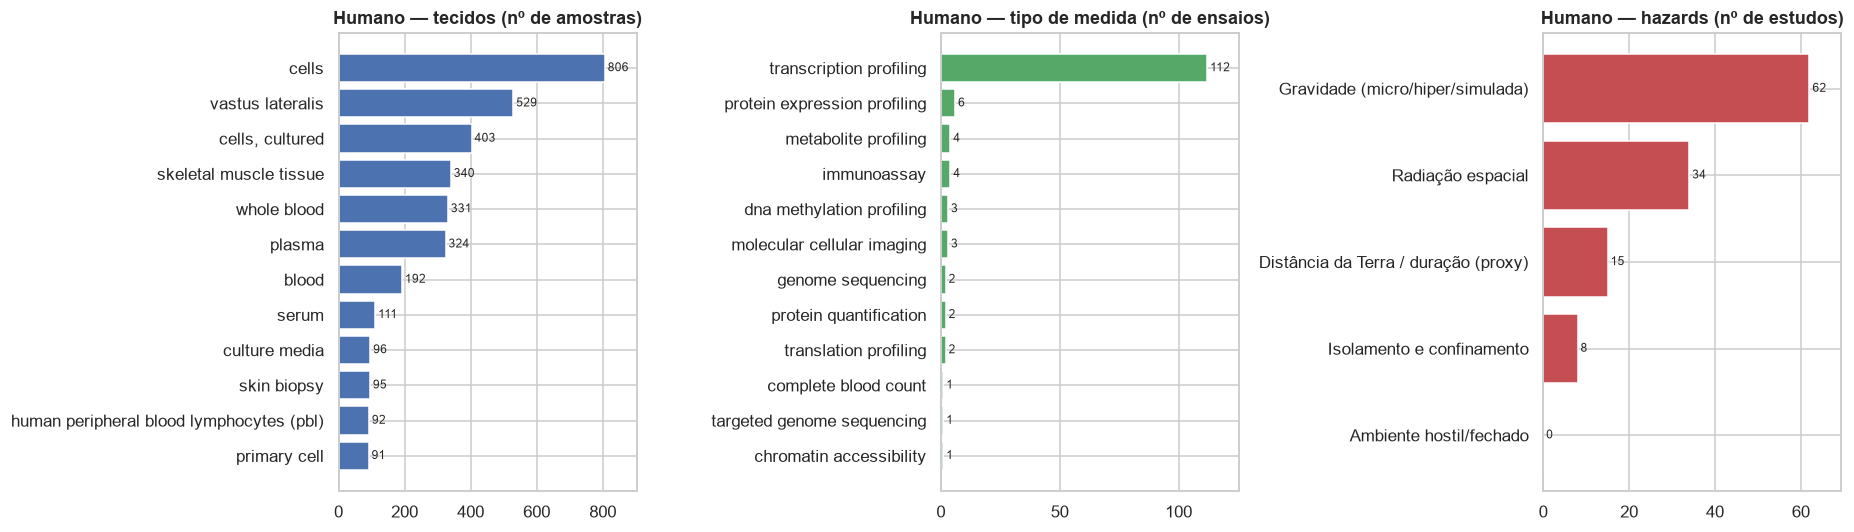


Estudos com amostras não invasivas: 72 — por grupo de organismo:


,n_estudos
org_group,
Humano,33
Camundongo,23
Micro-organismo,13
Rato,3


In [39]:
hum = ds[ds["org_group"] == "Humano"].copy()
print(f"Estudos humanos: {len(hum)} ({len(hum) / len(ds) * 100:.1f}% dos estudos) · amostras humanas: {int(hum['n_samples'].sum()):,}")
if len(hum):
    cols_show = ["n_samples", "n_assays", "tissues", "measurements", "has_quant", "release_year", "title"]
    display(hum.sort_values("n_samples", ascending=False)[cols_show].head(25))

    hs = samples[samples["org_group"] == "Humano"]
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    if hs["tissue_norm"].notna().any():
        barh(hs["tissue_norm"].value_counts(), "Humano — tecidos (nº de amostras)", top=12, ax=axes[0])
    hm = assays[assays["org_group"] == "Humano"]["measurement"].value_counts()
    if len(hm):
        barh(hm, "Humano — tipo de medida (nº de ensaios)", top=12, ax=axes[1], color=sns.color_palette("deep")[2])
    hz_h = pd.Series({k.replace("H: ", ""): int(hum[k].sum()) for k in HZ.values()})
    barh(hz_h, "Humano — hazards (nº de estudos)", top=6, ax=axes[2], color=sns.color_palette("deep")[3])
    plt.tight_layout(); plt.show()
else:
    print("Nenhum estudo humano identificado — confira a coluna de organismo.")

ni = ds[ds["noninvasive"]]
print(f"\nEstudos com amostras não invasivas: {len(ni)} — por grupo de organismo:")
display(ni["org_group"].value_counts().to_frame("n_estudos"))

### 7.6 Score de relevância (heurístico e transparente)
Soma de pontos por critério. **Edite `WEIGHTS`** para refletir o que o time considera mais importante.

Estudos com score ≥ 6.0: 241 de 641 (37.6%)


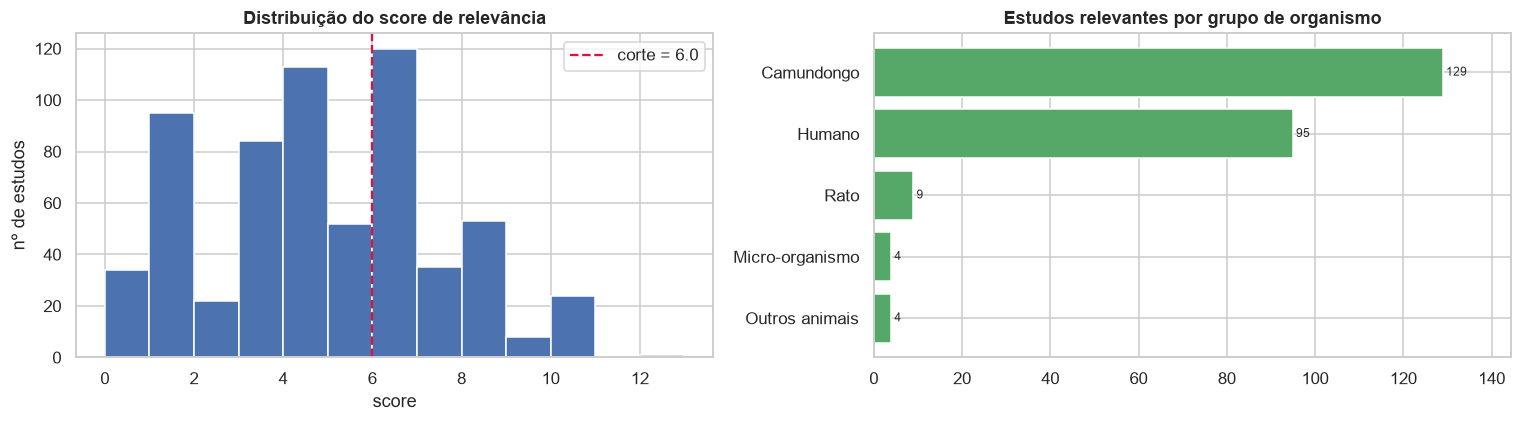


🏆 Top 25 estudos para o projeto:


,score,org_group,n_samples,tissues,measurements,has_quant,title
id.accession,,,,,,,
OSD-129,12.0,Humano,20,human peripheral blood lymphocytes (pbl),transcription profiling,True,
OSD-155,10.5,Humano,95,whole blood,transcription profiling,True,
OSD-157,10.5,Humano,75,whole blood,transcription profiling,True,
OSD-152,10.5,Humano,50,peripheral blood cell,transcription profiling,True,
OSD-542,10.5,Humano,30,whole blood,transcription profiling,True,
OSD-689,10.5,Humano,20,isolated cells,transcription profiling,True,
OSD-71,10.5,Humano,16,"blood, isolated leukocytes",transcription profiling,True,
OSD-182,10.5,Humano,12,cells,transcription profiling,True,
OSD-571,10.0,Humano,140,plasma,"genome sequencing, metabolite profiling, protein expression profiling, transcrip",False,


In [ ]:
WEIGHTS = {
    "humano": 4.0,               # Homo sapiens
    "mamifero_modelo": 2.0,      # camundongo / rato
    "outro_animal": 1.0,
    "hazard_cada": 1.5,          # por hazard coberto…
    "hazard_max": 3,             # …até este nº de hazards
    "sistema_cada": 1.0,         # por sistema do corpo coberto…
    "sistema_max": 3,            # …até este nº
    "dados_quantitativos": 2.0,  # existe counts/DGE baixável pela API
    "amostra_nao_invasiva": 2.0, # sangue/urina/saliva/cabelo/pele…
}
RELEVANCE_MIN = 6.0   # corte para o conjunto "relevante" exportado

hz_cols, sy_cols = list(HZ.values()), list(SY.values())

def relevance(r):
    s = 0.0
    if r["org_group"] == "Humano":                      s += WEIGHTS["humano"]
    elif r["org_group"] in ("Camundongo", "Rato"):      s += WEIGHTS["mamifero_modelo"]
    elif r["org_group"] == "Outros animais":            s += WEIGHTS["outro_animal"]
    s += min(int(r[hz_cols].sum()), WEIGHTS["hazard_max"]) * WEIGHTS["hazard_cada"]
    s += min(int(r[sy_cols].sum()), WEIGHTS["sistema_max"]) * WEIGHTS["sistema_cada"]
    s += WEIGHTS["dados_quantitativos"] * bool(r["has_quant"])
    s += WEIGHTS["amostra_nao_invasiva"] * bool(r["noninvasive"])
    return s

ds["score"] = ds.apply(relevance, axis=1)
ds_rank = ds.sort_values(["score", "n_samples"], ascending=False)
relevant = ds_rank[ds_rank["score"] >= RELEVANCE_MIN]
print(f"Estudos com score ≥ {RELEVANCE_MIN}: {len(relevant)} de {len(ds)} ({len(relevant) / len(ds) * 100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(ds["score"], bins=np.arange(0, ds["score"].max() + 1.5, 1), color=sns.color_palette("deep")[0], edgecolor="white")
axes[0].axvline(RELEVANCE_MIN, color="crimson", ls="--", label=f"corte = {RELEVANCE_MIN}"); axes[0].legend()
axes[0].set_title("Distribuição do score de relevância"); axes[0].set_xlabel("score"); axes[0].set_ylabel("nº de estudos")
barh(relevant["org_group"].value_counts(), "Estudos relevantes por grupo de organismo", top=8, ax=axes[1], color=sns.color_palette("deep")[2])
plt.tight_layout(); plt.show()

print("\n🏆 Top 25 estudos para o projeto:")
display(ds_rank[["score", "org_group", "n_samples", "tissues", "measurements", "has_quant", "title"]].head(25))

#### Arquivos reais dos estudos mais relevantes
Reaproveita o inventário da seção 6.2, agora sobre o ranking.

In [41]:
top_accs = ds_rank.head(N_DATASETS_FILE_INVENTORY).index.tolist()
inv_top = file_inventory(top_accs)
print(f"{len(inv_top):,} arquivos em {inv_top['accession'].nunique() if len(inv_top) else 0} estudos relevantes")
if len(inv_top):
    piv = (inv_top.groupby(["accession", "category"]).size().unstack(fill_value=0)
                  .reindex(top_accs).dropna(how="all"))
    keep = [c for c in ["DGE (expressão diferencial)", "Contagens normalizadas", "Contagens não normalizadas",
                        "PCA", "Tabela de amostras / contrastes", "Tabelas / planilhas (outros)",
                        "Reads/alinhamentos brutos", "Metadados ISA"] if c in piv.columns]
    if keep:
        display(piv[keep].head(25))

5,114 arquivos em 30 estudos relevantes


category,DGE (expressão diferencial),Contagens normalizadas,Contagens não normalizadas,PCA,Tabela de amostras / contrastes,Tabelas / planilhas (outros),Reads/alinhamentos brutos,Metadados ISA
accession,,,,,,,,
OSD-129,1,1,0,1,3,4,0,1
OSD-155,1,1,0,1,3,98,0,1
OSD-157,2,2,0,0,6,5,0,1
OSD-152,1,1,0,1,3,3,0,1
OSD-542,1,1,0,1,3,3,0,1
OSD-689,2,2,3,0,3,31,124,1
OSD-71,1,2,0,1,3,3,16,1
OSD-182,1,1,0,1,3,15,0,1
OSD-571,0,0,0,0,0,11,0,1


### 7.7 Procurando os **indicadores do desafio** (e proxies) nos metadados
Para cada família de biomarcador, contamos em quantos estudos ela aparece em quatro fontes: **colunas da tabela de amostras**, **valores dos fatores**, **título do estudo** e **nomes de ensaio**.

,colunas,valores de fator,título,nome do ensaio,UNIÃO (estudos),humanos na união
família,,,,,,
Temperatura / termorregulação,7,7,0,29,36,3
Nutrição,26,10,1,0,29,2
Estresse / humor / sono,2,4,5,12,20,1
Glicose / metabolismo,0,2,3,13,17,4
Cardiovascular (PA/FC),0,0,14,0,14,0
Osso / músculo,0,4,1,6,11,3
Imunidade / inflamação,0,0,5,0,5,1
Dano de DNA / radiação,0,0,4,0,4,0
Hematologia,0,0,0,0,0,0


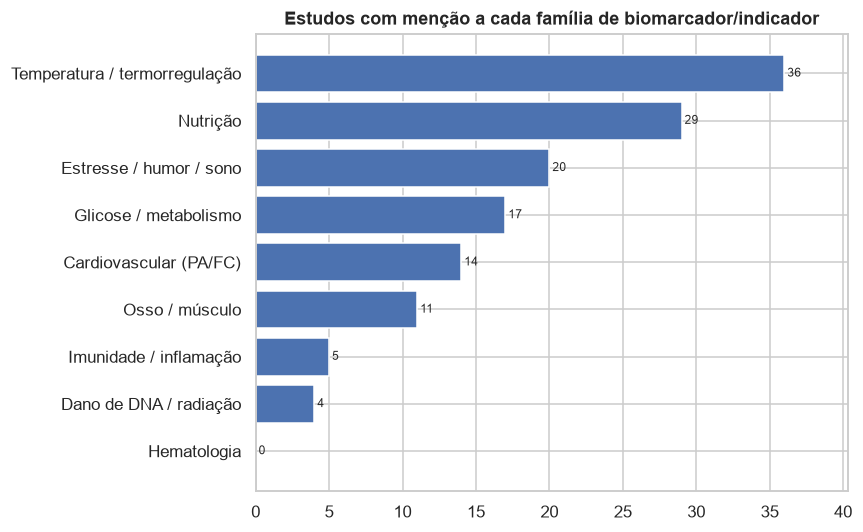

Exemplos de colunas encontradas por família:
  Estresse / humor / sono: ['study.characteristics.age at behavioral testing', 'study.factor value.minimized mechanical stress']
  Temperatura / termorregulação: ['study.factor value.housing temperature', 'study.factor value.temperature']
  Nutrição: ['study.characteristics.diet', 'study.factor value.diet', 'study.factor value.food deprivation', 'study.factor value.nutrient treatment']


In [42]:
tm_title = ds["title"].str.lower()
assay_l = assays["id.assay name"].astype(str).str.lower()
all_cols_l = {c: c.lower() for c in samples.columns if c.startswith("study.")}

rows, examples = [], {}
for fam, rx in BIOMARKERS.items():
    cols = [c for c, cl in all_cols_l.items() if re.search(rx, cl)]
    a_cols = set(samples.loc[samples[cols].notna().any(axis=1), "id.accession"]) if cols else set()
    a_vals = set(samples.loc[factor_text.str.contains(rx, regex=True, na=False), "id.accession"])
    a_title = set(ds.index[tm_title.str.contains(rx, regex=True, na=False)])
    a_assay = set(assays.loc[assay_l.str.contains(rx, regex=True), "id.accession"])
    union = a_cols | a_vals | a_title | a_assay
    rows.append({"família": fam, "colunas": len(a_cols), "valores de fator": len(a_vals),
                 "título": len(a_title), "nome do ensaio": len(a_assay), "UNIÃO (estudos)": len(union),
                 "humanos na união": int(ds.loc[ds.index.isin(union), "org_group"].eq("Humano").sum())})
    examples[fam] = cols[:4]
bio = pd.DataFrame(rows).set_index("família").sort_values("UNIÃO (estudos)", ascending=False)
display(bio)
barh(bio["UNIÃO (estudos)"], "Estudos com menção a cada família de biomarcador/indicador", top=10)
plt.tight_layout(); plt.show()

print("Exemplos de colunas encontradas por família:")
for k, v in examples.items():
    if v: print(f"  {k}: {v}")

#### Mapa **indicador do desafio → o que o OSDR oferece** (hipóteses a validar com a tabela acima)

| Indicador do desafio | Medido diretamente no OSDR? | Possíveis *proxies* moleculares/fisiológicos no OSDR | De onde virão os **limiares/orientações** |
|---|---|---|---|
| Pressão arterial, frequência cardíaca | **Não** (não é repositório de sinais vitais) | transcriptoma/proteoma de coração e vasos; marcadores de estresse cardiovascular | NASA HRP (Evidence Reports), literatura clínica |
| Glicose no sangue | **Não** diretamente | metabolômica, insulina/marcadores metabólicos em fígado, tecido adiposo, plasma | diretrizes clínicas + NASA HRP |
| Temperatura corporal | **Não** | genes de termorregulação/estresse; pouco provável de render algo útil | padrões médicos / NASA-STD-3001 |
| Horas de sono | **Não** | genes circadianos, melatonina (quando existirem) | NASA HRP (Sleep & Circadian), literatura |
| Humor / saúde comportamental | **Não** | cortisol, citocinas, estresse oxidativo; comportamento em modelos animais | NASA HRP (Behavioral Health) |
| Perda óssea / muscular | Parcialmente (ômicas de osso/músculo, imagens) | tecido musculoesquelético em roedores | NASA HRP (Bone/Muscle) |
| Dano por radiação | Parcialmente | dano de DNA, estresse oxidativo, estudos de irradiação | NASA HRP (Space Radiation) |
| Imunidade / inflamação | Parcialmente | amostras de sangue/baço/timo, citocinas | NASA HRP (Immune) |

**Leitura:** o OSDR serve melhor como **base de evidência** (quais tecidos/sistemas mudam sob cada hazard e por quê → texto explicativo, corpo clicável, "por que este exame importa") do que como fonte dos **valores numéricos** que o astronauta digita. Esses valores/limiares precisam de outra fonte (documentos da NASA HRP, padrões médicos, dados oficiais do desafio quando saírem).

## 8. Na prática: baixando uma **tabela quantitativa** real

Vamos pegar o estudo mais bem ranqueado que tenha **expressão diferencial (DGE)** e baixar a tabela pelo endpoint de dados (`/v2/query/data/`), com *fallback* para o download direto do arquivo listado em `/files/`.
Objetivo: ver o formato numérico real (colunas, escalas, identificadores de gene) e testar um gráfico típico (*volcano*).

In [43]:
def fetch_data_table(acc, datatype):
    """Tabela de dados via endpoint de dados (precisa resolver para um único arquivo)."""
    url = build_url("/v2/query/data/", [("id.accession", acc), ("file.datatype", datatype)])
    txt = http_get(url, timeout=300)
    return pd.read_csv(io.StringIO(txt), low_memory=False)

def fetch_table_from_files(acc, name_regex):
    """Fallback: baixa direto um CSV/TSV listado em /files/."""
    cand = [f for f in list_files(acc)
            if re.search(name_regex, f["file"], re.I) and re.search(r"\.(csv|tsv|txt)$", f["file"], re.I)]
    for f in cand[:3]:
        try:
            txt = http_get(f["url"], timeout=300)
            sep = "\t" if f["file"].lower().endswith((".tsv", ".txt")) else ","
            return pd.read_csv(io.StringIO(txt), sep=sep, low_memory=False), f["file"]
        except Exception:
            continue
    return None, None

dge, dge_src, dge_acc = None, None, None
cands = [a for a in ds_rank.index if ds_rank.loc[a, "has_dge"]][:8]
print("candidatos (DGE):", cands)
for acc in cands:
    try:
        dge = fetch_data_table(acc, "differential expression"); dge_src = "query/data"; dge_acc = acc; break
    except Exception as e:
        print(f"  {acc}: query/data falhou ({str(e)[:70]}) → tentando arquivos…")
        dge, fname = fetch_table_from_files(acc, r"differential_expression|dge")
        if dge is not None:
            dge_src, dge_acc = f"arquivo {fname}", acc; break

if dge is not None:
    print(f"\n✅ {dge_acc} · fonte: {dge_src} · {dge.shape[0]:,} linhas × {dge.shape[1]} colunas")
    display(dge.iloc[:6, :8])
    print("\nTipos de coluna:", dge.dtypes.astype(str).value_counts().to_dict())
else:
    print("⚠️ Nenhuma tabela DGE pôde ser baixada — siga para a seção 9 (o restante não depende disso).")

candidatos (DGE): ['OSD-129', 'OSD-155', 'OSD-157', 'OSD-152', 'OSD-542', 'OSD-689', 'OSD-71', 'OSD-182']

✅ OSD-129 · fonte: query/data · 45,015 linhas × 90 colunas


,OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/ENSEMBL,OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/SYMBOL,OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/GENENAME,OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/REFSEQ,OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/ENTREZID,OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/STRING_id,OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/GOSLIM_IDS,OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/ProbeUID
0,ENSG00000000003,TSPAN6,tetraspanin 6,NM_001278740|NM_001278741|NM_001278742|NM_001278743|NM_003270|NP_001265669|NP_00126567...,7105,9606.ENSP00000362111,GO:0031224|GO:0005887|GO:0031226|GO:0110165|GO:0071944|GO:0016020|GO:0016021|GO:0005886,8684
1,ENSG00000000003,TSPAN6,tetraspanin 6,NM_001278740|NM_001278741|NM_001278742|NM_001278743|NM_003270|NP_001265669|NP_00126567...,7105,9606.ENSP00000362111,GO:0031224|GO:0005887|GO:0031226|GO:0110165|GO:0071944|GO:0016020|GO:0016021|GO:0005886,7115
2,ENSG00000000005,TNMD,tenomodulin,NM_022144|NP_071427,64102,9606.ENSP00000362122,GO:0090288|GO:0008283|GO:0050789|GO:0009653|GO:1901342|GO:0035239|GO:0009966|GO:005067...,15220
3,ENSG00000000419,DPM1,"dolichyl-phosphate mannosyltransferase subunit 1, catalytic",NM_001317034|NM_001317035|NM_001317036|NM_003859|NP_001303963|NP_001303964|NP_00130396...,8813,9606.ENSP00000360644,GO:0016758|GO:0000030|GO:0016740|GO:0016757|GO:0003824,31586
4,ENSG00000000457,SCYL3,SCY1 like pseudokinase 3,NM_020423|NM_181093|NP_065156|NP_851607|XM_006711465|XM_011509801|XM_011509802|XM_0115...,57147,9606.ENSP00000356746,NaN,27096
5,ENSG00000000460,C1orf112,chromosome 1 open reading frame 112,NM_001320047|NM_001320048|NM_001320050|NM_001320051|NM_001363739|NM_001366768|NM_00136...,55732,9606.ENSP00000286031,NaN,7869



Tipos de coluna: {'float64': 80, 'str': 8, 'int64': 2}


gene: OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/ENSEMBL | log2FC: ['OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/Log2fc_(1G on Earth & cesium-137 gamma radiation)v(1G on Earth & non-irradiated)', 'OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/Log2fc_(1G on Earth & cesium-137 gamma radiation)v(uG by RWV & cesium-137 gamma radiation)', 'OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/Log2fc_(1G on Earth & cesium-137 gamma radiation)v(uG by RWV & non-irradiated)'] | p-ajustado: ['OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/Adj.p.value_(1G on Earth & cesium-137 gamma radiation)v(1G on Earth & non-irradiated)', 'OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/Adj.p.value_(1G on Earth & cesium-137 gamma radiation)v(uG by RWV & cesium-137 gamma radiation)', 'OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/Adj.p.value_(1G on Earth & cesium-137 gamma radiation)v(uG by RWV & no

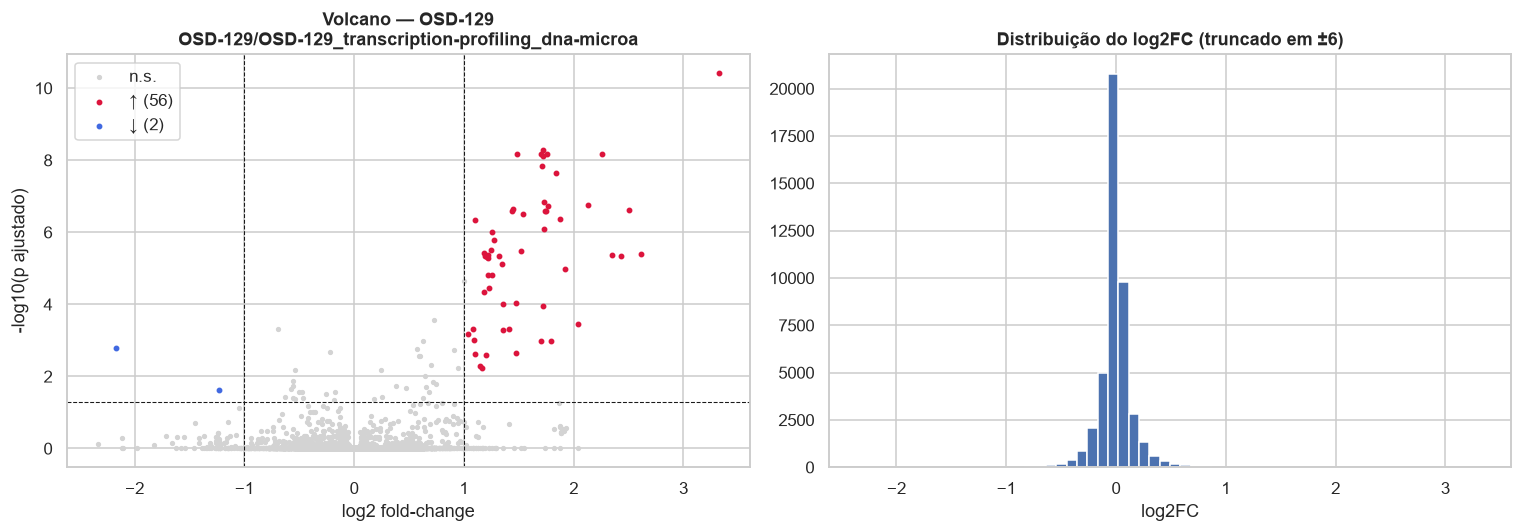

Genes com p-ajustado<0.05: 93 de 45,015 (0.2%)


,OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/ENSEMBL,log2FC,p_adj
16899,ENSG00000161513,3.318876,3.857030e-11
19295,ENSG00000167992,2.615599,3.994791e-06
5114,ENSG00000105327,2.499365,2.335343e-07
3909,ENSG00000100298,2.429380,4.560927e-06
7666,ENSG00000116717,2.345177,4.271220e-06
11093,ENSG00000134574,2.255064,6.706867e-09
21284,ENSG00000174307,2.125791,1.785437e-07
39347,NaN,2.039801,3.490154e-04
7853,ENSG00000117586,1.920151,1.049977e-05
3039,ENSG00000087088,1.874615,4.345869e-07


,OSD-129/OSD-129_transcription-profiling_dna-microarray_Agilent/ENSEMBL,log2FC,p_adj
20689,ENSG00000172183,-2.169731,0.001616
14115,ENSG00000145990,-1.233782,0.024016
27549,ENSG00000223609,-0.691273,0.000496
9225,ENSG00000125245,-0.632683,0.036705
3273,ENSG00000089685,-0.578556,0.022715
3267,ENSG00000089685,-0.561093,0.040360
3268,ENSG00000089685,-0.560988,0.018499
3270,ENSG00000089685,-0.553119,0.013436
3271,ENSG00000089685,-0.539022,0.006663
3269,ENSG00000089685,-0.536229,0.041937


In [44]:
if dge is not None:
    c_l2fc = pick_all(dge, r"log2fc|log2.?fold|logfc")
    c_padj = pick_all(dge, r"adj.?p|padj|fdr|q.?val")
    c_gene = pick(dge, r"^(symbol|gene.?symbol|gene|gene.?name|gene.?id|ensembl)$") or dge.columns[0]
    print("gene:", c_gene, "| log2FC:", c_l2fc[:3], "| p-ajustado:", c_padj[:3])

    if c_l2fc and c_padj:
        x = pd.to_numeric(dge[c_l2fc[0]], errors="coerce")
        p = pd.to_numeric(dge[c_padj[0]], errors="coerce").clip(lower=1e-300)
        y = -np.log10(p)
        ok = x.notna() & y.notna()
        up, dn = ok & (p < 0.05) & (x >= 1), ok & (p < 0.05) & (x <= -1)

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        axes[0].scatter(x[ok & ~up & ~dn], y[ok & ~up & ~dn], s=6, c="lightgrey", label="n.s.")
        axes[0].scatter(x[up], y[up], s=8, c="crimson", label=f"↑ ({up.sum()})")
        axes[0].scatter(x[dn], y[dn], s=8, c="royalblue", label=f"↓ ({dn.sum()})")
        axes[0].axhline(-np.log10(0.05), ls="--", c="k", lw=0.7); axes[0].axvline(-1, ls="--", c="k", lw=0.7); axes[0].axvline(1, ls="--", c="k", lw=0.7)
        axes[0].set_xlabel("log2 fold-change"); axes[0].set_ylabel("-log10(p ajustado)")
        axes[0].set_title(f"Volcano — {dge_acc}\n{c_l2fc[0][:50]}"); axes[0].legend()
        axes[1].hist(x.dropna().clip(-6, 6), bins=60, color=sns.color_palette("deep")[0], edgecolor="white")
        axes[1].set_title("Distribuição do log2FC (truncado em ±6)"); axes[1].set_xlabel("log2FC")
        plt.tight_layout(); plt.show()

        view = dge.assign(_l2fc=x, _padj=pd.to_numeric(dge[c_padj[0]], errors="coerce"))
        sig = view[view["_padj"] < 0.05]
        print(f"Genes com p-ajustado<0.05: {len(sig):,} de {len(view):,} ({len(sig) / max(len(view), 1) * 100:.1f}%)")
        display(sig.nlargest(10, "_l2fc")[[c_gene, "_l2fc", "_padj"]].rename(columns={"_l2fc": "log2FC", "_padj": "p_adj"}))
        display(sig.nsmallest(10, "_l2fc")[[c_gene, "_l2fc", "_padj"]].rename(columns={"_l2fc": "log2FC", "_padj": "p_adj"}))
    else:
        print("Não identifiquei as colunas log2FC / p-ajustado; inspecione dge.columns.")

### 8.1 (Opcional) Exemplo do tutorial: contagens de **vários estudos** juntos
O tutorial mostra que `unnormalized counts` é o único tipo que a API **funde entre estudos**. Exemplo: todos os estudos de camundongo, rim esquerdo, com fator *spaceflight*. Deixe `RUN_MULTI_STUDY_DEMO = True` para baixar (pode ser pesado).

In [45]:
RUN_MULTI_STUDY_DEMO = False
multi_params = [("study.characteristics.organism", "mus musculus"),
                ("study.characteristics.material type", "left kidney"),
                ("study.factor value.spaceflight", None),
                ("file.datatype", "unnormalized counts")]
print("Metadados :", build_url("/v2/query/metadata/", multi_params))
print("Dados     :", build_url("/v2/query/data/", multi_params))
if RUN_MULTI_STUDY_DEMO:
    mm = pd.read_csv(io.StringIO(http_get(build_url("/v2/query/data/", multi_params), timeout=600)), low_memory=False)
    print(mm.shape); display(mm.iloc[:5, :8])

Metadados : https://visualization.osdr.nasa.gov/biodata/api/v2/query/metadata/?study.characteristics.organism=mus%20musculus&study.characteristics.material%20type=left%20kidney&study.factor%20value.spaceflight&file.datatype=unnormalized%20counts
Dados     : https://visualization.osdr.nasa.gov/biodata/api/v2/query/data/?study.characteristics.organism=mus%20musculus&study.characteristics.material%20type=left%20kidney&study.factor%20value.spaceflight&file.datatype=unnormalized%20counts


## 9. Extração do que é relevante e exportação

Gera arquivos prontos para o time usar no app/protótipo:

| Arquivo | Conteúdo |
|---|---|
| `osdr_datasets_ranked.csv` | todos os estudos com score, flags de hazard/sistema, organismo, tecidos e dados disponíveis |
| `osdr_samples_relevant.csv` | amostras dos estudos com score ≥ `RELEVANCE_MIN` (colunas essenciais) |
| `osdr_kb_sistemas_hazards.json` | base de conhecimento: matriz sistema×hazard, top estudos, tipos de dado, famílias de biomarcadores |
| `osdr_file_inventory_top.csv` | arquivos (com URL de download) dos estudos do topo |

In [46]:
essential = ["id.accession", "id.assay name", "id.sample name", "organism_norm", "org_group",
             "tissue_norm", "spaceflight_norm", "noninvasive"] + hz_cols + sy_cols
essential = [c for c in essential if c in samples.columns]
samples_rel = samples[samples["id.accession"].isin(relevant.index)][essential]

ds_rank.reset_index().rename(columns={"index": "accession", "id.accession": "accession"}).to_csv(f"{OUT_DIR}/osdr_datasets_ranked.csv", index=False)
samples_rel.to_csv(f"{OUT_DIR}/osdr_samples_relevant.csv", index=False)
if len(inv_top):
    inv_top.to_csv(f"{OUT_DIR}/osdr_file_inventory_top.csv", index=False)

kb = {
    "gerado_em": pd.Timestamp.now().isoformat(timespec="seconds"),
    "n_estudos_total": int(len(ds)), "n_amostras_total": int(len(samples)),
    "pesos_score": WEIGHTS, "corte_relevancia": RELEVANCE_MIN,
    "matriz_sistema_hazard_todos": M_all.to_dict(),
    "matriz_sistema_hazard_mamiferos": M_m.to_dict(),
    "estudos_por_grupo_organismo": ds["org_group"].value_counts().to_dict(),
    "tipos_de_dado": (dt_counts.to_dict() if ft is not None else {}),
    "biomarcadores_estudos": bio["UNIÃO (estudos)"].to_dict(),
    "top_estudos": ds_rank.head(30).reset_index().rename(columns={"index": "accession", "id.accession": "accession"})
                          [["accession", "score", "org_group", "n_samples", "tissues", "measurements", "title"]].to_dict("records"),
}
with open(f"{OUT_DIR}/osdr_kb_sistemas_hazards.json", "w", encoding="utf-8") as f:
    json.dump(kb, f, ensure_ascii=False, indent=2, default=str)

print("Arquivos gerados em ./outputs:")
for fn in sorted(os.listdir(OUT_DIR)):
    print(f"  - {fn:40s} {os.path.getsize(os.path.join(OUT_DIR, fn)) / 1024:9.1f} KB")

# download automático no Colab (ignorado fora do Colab)
try:
    import shutil
    from google.colab import files
    shutil.make_archive("osdr_outputs", "zip", OUT_DIR)
    files.download("osdr_outputs.zip")
except Exception:
    print("\n(fora do Colab: pegue os arquivos na pasta ./outputs)")

Arquivos gerados em ./outputs:
  - osdr_datasets_ranked.csv                     150.7 KB
  - osdr_file_inventory_top.csv                 1288.4 KB
  - osdr_kb_sistemas_hazards.json                 13.0 KB
  - osdr_samples_relevant.csv                   2923.5 KB

(fora do Colab: pegue os arquivos na pasta ./outputs)


## 10. Como ler os resultados e próximos passos

### Checklist de decisões (preencha com o time depois de rodar)
- [ ] **Quantos estudos humanos** existem e quais tecidos/ensaios eles trazem? (7.5)
- [ ] Quais **sistemas do corpo** têm mais evidência sob cada hazard? → candidatos às regiões clicáveis do corpo humano (7.4)
- [ ] Que **famílias de biomarcadores** aparecem mais (inflamação, metabolismo, estresse, osso/músculo…)? → candidatos a "indicadores" explicáveis no app (7.7)
- [ ] Que **tabelas numéricas** podem ser baixadas direto pela API (counts/DGE/PCA) e em quantos estudos? (6.1, 8)
- [ ] Quais **10–20 estudos** do ranking (7.6) vamos ler a fundo e citar no app?

### Ideias de uso no produto
1. **Corpo humano clicável**: cada região mostra função, o hazard que mais a afeta e "o que o OSDR observou" (nº de estudos + 2–3 estudos de referência com link `https://osdr.nasa.gov/bio/repo/data/studies/OSD-###`).
2. **Explicações para leigos**: usar a matriz sistema×hazard e os títulos dos estudos como base de texto ("por que medir X").
3. **Alertas e orientações**: os *valores* e limiares vêm de outras fontes (NASA HRP, padrões médicos); o OSDR dá a **evidência biológica** do porquê.
4. **Gamificação/rotina**: derivar tarefas de medição das famílias de biomarcadores mais recorrentes por hazard.

### Limitações a lembrar
- A classificação por regex é **heurística** (pode haver falsos positivos/negativos, principalmente em "Ambiente hostil" e "Distância/duração").
- O OSDR é dominado por **modelos animais, plantas e micro-organismos**; tradução para humanos exige cuidado e é preciso deixar isso claro no app.
- Metadados variam muito entre estudos (muitas colunas esparsas); evite depender de um único campo.
- A API evolui: se algum endpoint mudar, ajuste `query_table()` (único ponto de acesso às consultas) e confira a [especificação](https://visualization.osdr.nasa.gov/biodata/api/).
- Quando os dados oficiais do desafio saírem, este notebook serve de **modelo de EDA**: troque `http_get/query_table` pela nova fonte e reaproveite a seção 7.

*Fontes:* NASA OSDR Biological Data API · OSDR Tutorials (Use the Biological Data API) · NASA Human Research Program (5 hazards of human spaceflight).